In [ ]:
import os
os.makedirs("/content/data", exist_ok=True)

# SECTION 3: Dataset Construction and Feature Selection

In [ ]:
import numpy as np
import pandas as pd

raw = pd.read_csv("/content/data/tmdb_movies.csv")
raw = raw.rename(columns=str.strip)

# column: (meaning, kind, API source, planned use)
info = {
 "id": ("TMDB movie identifier", "Identifier", "id", "Exclude: label only"),
 "title": ("Movie title", "Text", "title", "Exclude: label only"),
 "release_date": ("Release date (YYYY-MM-DD)", "Date", "release_date", "Derive year and month"),
 "budget": ("Production budget in US dollars; 0 = unknown", "Numerical", "budget", "Candidate feature"),
 "revenue": ("Box office revenue in US dollars; 0 = unknown", "Numerical", "revenue", "Target"),
 "runtime": ("Length in minutes; 0 would mean unknown", "Numerical", "runtime", "Candidate feature"),
 "popularity": ("TMDB activity score at collection time", "Numerical", "popularity", "Excluded from model inputs: leakage risk"),
 "vote_average": ("Mean TMDB user rating (0-10)", "Numerical", "vote_average", "Excluded from model inputs: leakage risk"),
 "vote_count": ("Number of TMDB user votes", "Numerical", "vote_count", "Excluded from model inputs: leakage risk"),
 "original_language": ("Original language code", "Categorical", "original_language", "Candidate: encode"),
 "status": ("Release status", "Categorical", "status", "Exclude if constant"),
 "adult": ("TMDB adult-content flag", "Boolean", "adult", "Exclude if constant"),
 "in_collection": ("True if part of a TMDB collection", "Boolean", "belongs_to_collection", "Candidate; check it was known before release"),
 "genres": ("Genre names separated by |", "Categorical (multi-valued)", "genres", "Candidate: multi-hot encode"),
 "production_companies": ("Producing companies separated by |", "Categorical (multi-valued)", "production_companies", "Candidate: group rare values"),
 "production_countries": ("Country codes separated by |", "Categorical (multi-valued)", "production_countries", "Candidate: group rare values"),
 "spoken_languages": ("Number of spoken languages; 0 = none listed", "Numerical (count)", "spoken_languages", "Candidate feature"),
 "director": ("First listed director", "Categorical", "credits.crew", "Candidate: many unique values"),
 "top_cast": ("First three cast names separated by |", "Categorical (multi-valued)", "credits.cast", "Candidate: many unique values"),
 "cast_size": ("Number of cast entries on TMDB", "Numerical (count)", "credits.cast", "Candidate; may be edited after release"),
 "overview": ("Plot summary", "Text", "overview", "Not used unless text features are built"),
 "tagline": ("Promotional tagline", "Text", "tagline", "Not used unless text features are built"),
 "collected_at": ("Time the script fetched the record", "Date-time (metadata)", "added by us", "Exclude: metadata"),
}

dictionary = pd.DataFrame(info, index=["meaning", "kind", "api_source", "use"]).T
dictionary.insert(2, "pandas_dtype", raw.dtypes.astype(str))
dictionary["example"] = raw.iloc[0].astype(str).str.slice(0, 40)

assert set(dictionary.index) == set(raw.columns)   # every column is documented

derived = pd.DataFrame([
    ["release_year", "Year of release", "Numerical (date-derived)", "release_date"],
    ["release_month", "Month of release (1-12)", "Categorical (date-derived)", "release_date"],
    ["n_genres", "Number of genres listed", "Numerical (count)", "genres"],
    ["n_companies", "Number of production companies", "Numerical (count)", "production_companies"],
    ["g_ columns", "1 if the film has that genre", "Binary (0/1)", "genres"],
    ["c_ columns", "1 if the film lists that country (frequent countries only)", "Binary (0/1)", "production_countries"],
    ["budget_was_missing", "True if the budget was originally unknown", "Boolean", "budget"],
], columns=["attribute", "meaning", "kind", "derived_from"]).set_index("attribute")

pd.set_option("display.max_colwidth", None)
display(dictionary)
display(derived)

,meaning,kind,pandas_dtype,api_source,use,example
id,TMDB movie identifier,Identifier,int64,id,Exclude: label only,293660
title,Movie title,Text,object,title,Exclude: label only,Deadpool
release_date,Release date (YYYY-MM-DD),Date,object,release_date,Derive year and month,2016-02-09
budget,Production budget in US dollars; 0 = unknown,Numerical,int64,budget,Candidate feature,58000000
revenue,Box office revenue in US dollars; 0 = unknown,Numerical,int64,revenue,Target,782837347
runtime,Length in minutes; 0 would mean unknown,Numerical,int64,runtime,Candidate feature,108
popularity,TMDB activity score at collection time,Numerical,float64,popularity,Excluded from model inputs: leakage risk,21.4464
vote_average,Mean TMDB user rating (0-10),Numerical,float64,vote_average,Excluded from model inputs: leakage risk,7.6
vote_count,Number of TMDB user votes,Numerical,int64,vote_count,Excluded from model inputs: leakage risk,33670
original_language,Original language code,Categorical,object,original_language,Candidate: encode,en


,meaning,kind,derived_from
attribute,,,
release_year,Year of release,Numerical (date-derived),release_date
release_month,Month of release (1-12),Categorical (date-derived),release_date
n_genres,Number of genres listed,Numerical (count),genres
n_companies,Number of production companies,Numerical (count),production_companies
g_ columns,1 if the film has that genre,Binary (0/1),genres
c_ columns,1 if the film lists that country (frequent countries only),Binary (0/1),production_countries
budget_was_missing,True if the budget was originally unknown,Boolean,budget


I did this because the pandas data type doesn't explain what a column means. For example, release_date is stored as an object but it is a date. The output shows each column's meaning, type, source, planned use and an example, and revenue is marked as the target. From this, I plan not to use id and title as ordinary predictors because they are only labels. popularity, vote_average and vote_count are excluded from the model inputs in Section 5 to avoid leakage. The planned uses show initial choices, and Section 5 shows the inputs currently prepared. The table of additional features also describes features that are created later in the notebook.

# SECTION 4. Data Understanding and Description

In [ ]:
print("Shape (rows, columns):", raw.shape)
print("\nColumn names:")
print(raw.columns.tolist())

Shape (rows, columns): (1100, 23)

Column names:
['id', 'title', 'release_date', 'budget', 'revenue', 'runtime', 'popularity', 'vote_average', 'vote_count', 'original_language', 'status', 'adult', 'in_collection', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'director', 'top_cast', 'cast_size', 'overview', 'tagline', 'collected_at']


I checked the shape and column names of the original dataset. I did this to confirm that it loaded correctly and to understand its structure before analysing it. The output shows 1,100 rows and 23 columns, where each row represents one movie. The columns include identifiers and titles, release information, money values such as budget and revenue, audience statistics, movie characteristics such as genres and runtime, production and cast details, text fields and the collection time. This shows that the dataset contains different kinds of data, so the columns will need different processing.

In [ ]:
print("First five records:")
display(raw.head())

print("Last five records:")
display(raw.tail())

First five records:


,id,title,release_date,budget,revenue,runtime,popularity,vote_average,vote_count,original_language,...,genres,production_companies,production_countries,spoken_languages,director,top_cast,cast_size,overview,tagline,collected_at
0,293660,Deadpool,2016-02-09,58000000,782837347,108,21.4464,7.600,33670,en,...,Action|Adventure|Comedy,20th Century Fox|The Donners' Company|Genre Films|Marvel Entertainment,US,1,Tim Miller,Ryan Reynolds|Morena Baccarin|Ed Skrein,52,"The origin story of former Special Forces operative turned mercenary Wade Wilson, who, after being subjected to a rogue experiment that leaves him with accelerated healing powers, adopts the alter ego Deadpool. Armed with his new abilities and a dark, twisted sense of humor, Deadpool hunts down the man who nearly destroyed his life.",Feel the love.,2026-11-23T16:03:33
1,271110,Captain America: Civil War,2016-04-27,250000000,1155046416,147,25.9850,7.456,24905,en,...,Adventure|Action|Science Fiction,Marvel Studios|Vita-Ray Dutch Productions III|Studio Babelsberg,US|DE,4,Joe Russo,Chris Evans|Robert Downey Jr.|Scarlett Johansson,104,"Following the events of Age of Ultron, the collective governments of the world pass an act designed to regulate all superhuman activity. This polarizes opinion amongst the Avengers, causing two factions to side with Iron Man or Captain America, which causes an epic battle between former allies.",United we stand. Divided we fall.,2026-11-23T16:03:33
2,284052,Doctor Strange,2016-10-25,180000000,676343174,115,17.4811,7.424,24248,en,...,Fantasy|Adventure|Action,Marvel Studios,US,1,Scott Derrickson,Benedict Cumberbatch|Chiwetel Ejiofor|Rachel McAdams,44,"After his career is destroyed, a brilliant but arrogant surgeon gets a new lease on life when a sorcerer takes him under her wing and trains him to defend the world against evil.",The impossibilities are endless.,2026-11-23T16:03:33
3,297761,Suicide Squad,2016-08-03,175000000,749200054,122,11.9384,5.916,22654,en,...,Action|Adventure|Fantasy,Warner Bros. Pictures|DC Films|Atlas Entertainment|RatPac-Dune Entertainment,US,3,David Ayer,Will Smith|Jared Leto|Margot Robbie,106,"From DC Comics comes the Suicide Squad, an antihero team of incarcerated supervillains who act as deniable assets for the United States government, undertaking high-risk black ops missions in exchange for commuted prison sentences.",Worst. Heroes. Ever.,2026-11-23T16:03:33
4,329865,Arrival,2016-11-10,47000000,203388186,116,22.4036,7.638,20230,en,...,Drama|Science Fiction|Mystery,FilmNation Entertainment|Lava Bear Films|21 Laps Entertainment,US,3,Denis Villeneuve,Amy Adams|Jeremy Renner|Forest Whitaker,72,"Taking place after alien crafts land around the world, an expert linguist is recruited by the military to determine whether they come in peace or are a threat.",Why are they here?,2026-11-23T16:03:33


Last five records:


,id,title,release_date,budget,revenue,runtime,popularity,vote_average,vote_count,original_language,...,genres,production_companies,production_countries,spoken_languages,director,top_cast,cast_size,overview,tagline,collected_at
1095,1248832,Digger,2026-09-28,180000000,50850116,129,23.0364,7.500,538,en,...,Comedy|Drama,Warner Bros. Pictures|Legendary Pictures|Domain Entertainment,US,4,Alejandro G. Iñárritu,Tom Cruise|Riz Ahmed|John Goodman,89,The most powerful man in the world embarks on a frantic mission to prove he is humanity's savior before the disaster he's unleashed destroys everything.,A man. A plan. A meltdown.,2026-11-23T16:06:30
1096,1560520,Batman: Knightfall Part 1: Knightfall,2026-08-25,0,0,79,26.7671,9.093,512,en,...,Animation|Action|Adventure|Drama,Warner Bros. Animation|DC,US,2,Jeff Wamester,Anson Mount|Michael Mando|Pablo Schreiber,22,"Arkham Asylum has been destroyed, and all its inmates have been unleashed upon Gotham City. As Batman races to round up some of his greatest enemies, he is pushed to his physical and mental limits and into a final confrontation with a new threat: the man called Bane!",NaN,2026-11-23T16:06:30
1097,949838,72 HOURS,2026-07-20,0,0,105,7.3534,6.718,512,en,...,Comedy|Crime,Sony Pictures|Davis Entertainment|Counterbalance Entertainment|HartBeat Productions|Will Packer Productions|The Story Company,US,1,Tim Story,Kevin Hart|Marcello Hernández|Mason Gooding,52,"To save his career, a 40-year-old ad exec joins a crew of twentysomethings for a wild Miami bachelor party after they mistakenly add him to a group chat.",The night is young. He isn't.,2026-11-23T16:06:31
1098,1115544,Mike & Nick & Nick & Alice,2026-03-14,0,0,107,8.1309,6.666,508,en,...,Comedy|Science Fiction|Action,20th Century Studios|Mad Chance,US,1,BenDavid Grabinski,James Marsden|Vince Vaughn|Eiza González,35,"Two gangsters and the woman they love try to survive the most dangerous night of their lives. As if that wasn’t enough, there’s one wild ingredient added to the mix: a time machine.","A time-traveling, double-crossing, ass-kicking comedy.",2026-11-23T16:06:31
1099,1116201,Iron Lung,2026-01-30,3000000,51226173,125,7.5192,6.800,491,en,...,Horror|Mystery|Science Fiction,Markiplier Studios,US,1,Mark Fischbach,Mark Fischbach|Caroline Kaplan|Troy Baker,23,"In a post-apocalyptic future where an event known as ""The Quiet Rapture"" caused all known stars and habitable planets in the universe to disappear, a convict is sent to search an ocean of blood discovered on a desolate moon, using a small submarine nicknamed the ""Iron Lung"".",This is not an expedition. It's an execution.,2026-11-23T16:06:31


I displayed the first and last five records to check that the data loaded correctly. The first five are 2016 releases and the last five are from 2026. In these rows, the 2016 films have much higher vote counts. Three of the last five have 0 for budget and revenue, which means these values are unknown. One tagline is also missing (NaN). Ten rows are too few to draw conclusions about the whole dataset.

In [ ]:
raw.info(memory_usage="deep")

total_memory = raw.memory_usage(deep=True).sum()
print(f"\nTotal memory: {total_memory / 1024**2:.2f} MB")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1100 non-null   int64  
 1   title                 1100 non-null   object 
 2   release_date          1100 non-null   object 
 3   budget                1100 non-null   int64  
 4   revenue               1100 non-null   int64  
 5   runtime               1100 non-null   int64  
 6   popularity            1100 non-null   float64
 7   vote_average          1100 non-null   float64
 8   vote_count            1100 non-null   int64  
 9   original_language     1100 non-null   object 
 10  status                1100 non-null   object 
 11  adult                 1100 non-null   bool   
 12  in_collection         1100 non-null   bool   
 13  genres                1100 non-null   object 
 14  production_companies  1099 non-null   object 
 15  production_countries 

I used info() and checked memory usage to understand the dataset's structure, data types and size. It has 1,100 rows and 23 columns: 7 integer, 2 float, 2 Boolean and 12 object columns. Four columns have empty values: production_companies (1), production_countries (2), top_cast (2) and tagline (43). Non-null does not always mean the value is known, because unknown budgets and revenues are stored as 0. The dataset uses about 1.25 MB of memory, which is small.

In [ ]:
types = {
    "Numerical": ["budget", "revenue", "runtime", "popularity", "vote_average",
                  "vote_count", "spoken_languages", "cast_size"],
    "Categorical (single)": ["original_language", "status", "director"],
    "Categorical (multi-valued)": ["genres", "production_companies",
                                   "production_countries", "top_cast"],
    "Boolean": ["adult", "in_collection"],
    "Date / time": ["release_date", "collected_at"],
    "Identifier / free text": ["id", "title", "overview", "tagline"],
}

for kind, columns in types.items():
    print(f"{kind} ({len(columns)}): {', '.join(columns)}")

print("Total:", sum(len(columns) for columns in types.values()))

Numerical (8): budget, revenue, runtime, popularity, vote_average, vote_count, spoken_languages, cast_size
Categorical (single) (3): original_language, status, director
Categorical (multi-valued) (4): genres, production_companies, production_countries, top_cast
Boolean (2): adult, in_collection
Date / time (2): release_date, collected_at
Identifier / free text (4): id, title, overview, tagline
Total: 23


I grouped the columns by what they mean, because different kinds of data need different processing. The pandas data type alone is not enough. For example, id is stored as a number but is only a label.

In [ ]:
print("Numerical columns:")
display(raw[types["Numerical"]].describe().T.round(2))

categorical = types["Categorical (single)"] + types["Categorical (multi-valued)"]
print("Categorical columns:")
display(raw[categorical].describe().T)

Numerical columns:


,count,mean,std,min,25%,50%,75%,max
budget,1100.0,6.174349e+07,7.475007e+07,0.00,9000000.00,35000000.00,9.000000e+07,6.588000e+08
revenue,1100.0,1.882757e+08,3.210666e+08,0.00,6151455.00,60832731.00,2.139270e+08,2.942661e+09
runtime,1100.0,1.151200e+02,2.031000e+01,12.00,102.00,112.00,1.260000e+02,2.420000e+02
popularity,1100.0,1.301000e+01,2.738000e+01,0.03,5.51,8.08,1.253000e+01,4.997100e+02
vote_average,1100.0,6.940000e+00,6.700000e-01,3.98,6.49,6.94,7.400000e+00,9.090000e+00
vote_count,1100.0,4.637110e+03,4.396570e+03,491.00,1865.00,3184.50,5.588250e+03,3.367000e+04
spoken_languages,1100.0,1.730000e+00,1.230000e+00,0.00,1.00,1.00,2.000000e+00,9.000000e+00
cast_size,1100.0,4.845000e+01,3.407000e+01,0.00,29.00,41.00,6.000000e+01,3.940000e+02


Categorical columns:


,count,unique,top,freq
original_language,1100,16,en,1021
status,1100,1,Released,1100
director,1100,676,Guy Ritchie,9
genres,1100,494,Drama,33
production_companies,1099,993,Pixar,14
production_countries,1098,176,US,650
top_cast,1098,1079,Chris Pratt|Zoe Saldaña|Dave Bautista,2


I generated summary statistics to understand the numerical and categorical columns. These use the raw data, so zeros are included. Budget has a mean of about 61.7 million and a median of 35 million, while revenue has a mean of about 188.3 million and a median of 60.8 million. Means far above medians suggest right skew, where a few large values pull the mean up. The zeros in budget and revenue also affect these figures. Popularity has a median of 8.08 but a maximum of 499.71. English is the most common language (1,021 films), and status has only one value, so it is not useful for prediction. Genres, companies, countries and cast contain combined values, so they need to be split before counting each item.

In [ ]:
single = types["Categorical (single)"] + types["Boolean"]
multi = types["Categorical (multi-valued)"]

# one column at a time; multi-valued ones are split at "|"
values = {c: raw[c] for c in single}
for c in multi:
    values[c] = raw[c].dropna().str.split("|").explode()

print("Number of unique values:")
display(pd.Series({c: s.nunique() for c, s in values.items()}, name="unique_values").to_frame())

for c, s in values.items():
    print(f"\nTop values in {c}:")
    print(s.value_counts().head(10).to_string())

Number of unique values:


,unique_values
original_language,16
status,1
director,676
adult,1
in_collection,2
genres,18
production_companies,1543
production_countries,54
top_cast,1734



Top values in original_language:
original_language
en    1021
ja      17
fr      14
es      13
ko       9
it       6
no       4
zh       3
fi       2
pl       2

Top values in status:
status
Released    1100

Top values in director:
director
Guy Ritchie           9
Zack Snyder           6
Ridley Scott          6
Steven Spielberg      6
Antoine Fuqua         6
Ric Roman Waugh       5
Yorgos Lanthimos      5
David F. Sandberg     5
M. Night Shyamalan    5
Paul Feig             5

Top values in adult:
adult
False    1100

Top values in in_collection:
in_collection
False    708
True     392

Top values in genres:
genres
Action             375
Drama              345
Thriller           327
Comedy             315
Adventure          297
Horror             228
Science Fiction    216
Fantasy            170
Crime              165
Mystery            125

Top values in production_companies:
production_companies
Universal Pictures       73
Warner Bros. Pictures    66
Columbia Pictures        64
Par

I counted the unique values and the most frequent values in the categorical and Boolean columns. Multi-value columns were split so that each genre, company, country and actor is counted separately. English is the original language of 1,021 films (92.8%), and 1,002 films (91.1%) list the US as a production country, so the dataset is heavily English and US based. Action (375), Drama (345) and Thriller (327) are the most common genres. A film can have several genres or countries, so these counts can add up to more than 1,100. Director (676), production companies (1,543) and top cast (1,734) have many unique values, so one-hot encoding all of them would create too many columns. Grouping rare values is one option. status and adult have only one value each, so they are not useful for prediction. top_cast includes only the first three listed cast members of each film.

# SECTION 5:  Data Cleaning and Preprocessing

5A,B

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv("/content/data/tmdb_movies.csv")
df.columns = df.columns.str.strip()

df_backup = df.copy()

cols_with_zeros = ["budget", "revenue", "runtime"]

empty_counts = df.isna().sum()

zero_counts = (df[cols_with_zeros] == 0).sum()

summary_table = pd.DataFrame({"empty": empty_counts, "zeros": zero_counts})
summary_table = summary_table.fillna(0).astype(int)

summary_table["total_missing"] = summary_table["empty"] + summary_table["zeros"]
summary_table["percent_missing"] = (summary_table["total_missing"] / len(df) * 100).round(2)

print(summary_table[summary_table["total_missing"] > 0])

                      empty  zeros  total_missing  percent_missing
budget                    0    159            159            14.45
production_companies      1      0              1             0.09
production_countries      2      0              2             0.18
revenue                   0    201            201            18.27
tagline                  43      0             43             3.91
top_cast                  2      0              2             0.18


Before changing anything, I made a backup copy of the data and counted how much is missing in each column. I counted two things: cells that are empty, and zeros in budget, revenue and runtime, because TMDB writes 0 when it does not know these values, even though a movie cannot really have a budget, revenue or runtime of 0. I only checked zeros in these three columns because in other columns a zero can be a real value. The table shows that budget has 159 missing values (14.45%) and revenue has 201 (18.27%), while runtime has none. The text columns have only a few empty cells: tagline 43 (3.91%), production_countries 2, top_cast 2 and production_companies 1. This tells me the zeros in budget and revenue are the main missing-data problem, and that 899 of the 1,100 movies have a real revenue value, which is enough to use revenue as the target.

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated movie ids:", df["id"].duplicated().sum())

rows_before = len(df)
df = df.drop_duplicates()
print("Removed:", rows_before - len(df), " rows left:", len(df))

Exact duplicate rows: 0
Repeated movie ids: 0
Removed: 0  rows left: 1100


I checked whether any movie appears more than once, both as an exact copy of a whole row and as a repeated movie id, and then dropped any exact duplicate rows. I did this because duplicate movies would be counted twice and could give the models an unfair advantage when the same movie lands in both the training and test sets. The output shows 0 duplicate rows and 0 repeated ids, so no rows were removed and 1,100 rows are left. This is what I expected, because I already removed duplicate ids when I collected the movie ids, so the data had no duplicates to remove.

In [ ]:
df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)

print(df[cols_with_zeros].isna().sum())
print("Rows with a real revenue:", df["revenue"].notna().sum())

budget     159
revenue    201
runtime      0
dtype: int64
Rows with a real revenue: 899


I replaced the zeros in budget, revenue and runtime with proper missing values (NaN). I did this because TMDB writes 0 when it does not know a value, but a movie cannot really have a budget, revenue or runtime of 0, so leaving the zeros would make the averages, charts and models wrong. The output shows that budget now has 159 missing values, revenue has 201 and runtime has 0, which matches the zero counts I measured before, and that 899 movies have a real revenue value. Since I plan to use revenue as the target, the movies with a missing revenue will be left out of model training and testing, and the rest will be used.

In [ ]:

df_copy = df.copy()

cols = [
    "budget",
    "runtime",
    "popularity",
    "vote_average",
    "vote_count",
    "cast_size"
]

rng = np.random.default_rng(900)

for col in cols:
    valid_rows = df_copy.index[df_copy[col].notna()]
    missing_count = round(0.05 * len(valid_rows))

    missing_rows = rng.choice(
        valid_rows.to_numpy(),
        size=missing_count,
        replace=False
    )

    df_copy.loc[missing_rows, col] = np.nan

comparison = pd.DataFrame({
    "Before": df[cols].isna().sum(),
    "After": df_copy[cols].isna().sum()
})

print(comparison)

print("\nRevenue missing values:", df_copy["revenue"].isna().sum())

df_copy.to_csv("/content/data/tmdb_movies_with_missing.csv", index=False)


              Before  After
budget           159    206
runtime            0     55
popularity         0     55
vote_average       0     55
vote_count         0     55
cast_size          0     55

Revenue missing values: 201


To evaluate how well our data handles missing values, we created a separate copy of the original dataset and introduced approximately 5% artificial missing values in selected input features. Randomly selected non-missing values in each selected column were replaced with NaN, while the original dataset was kept unchanged. We then compared the number of missing values before and after this process to observe the increase in missing data. We also verified that the target variable (revenue) remained unaffected. This modified dataset will be used to evaluate different missing value handling and imputation techniques.

In [ ]:
df_copy.dtypes

,0
id,int64
title,object
release_date,object
budget,float64
revenue,float64
runtime,float64
popularity,float64
vote_average,float64
vote_count,float64
original_language,object


## Section 10 Train-Test split

In [ ]:
df_model = df_copy.dropna(subset=["revenue"]).copy()

df_model["release_date"] = pd.to_datetime(df_model["release_date"])
df_model["release_year"] = df_model["release_date"].dt.year
df_model["release_month"] = df_model["release_date"].dt.month
df_model["n_genres"] = df_model["genres"].fillna("").apply(lambda g: len(g.split("|")) if g else 0)

print(df_model.shape)

from sklearn.model_selection import train_test_split

SEED = 900
X = df_model.drop(columns=["revenue"])
y = df_model["revenue"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()
print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

(899, 26)

Training features: (719, 25)
Testing features: (180, 25)
Training target: (719,)
Testing target: (180,)


## 5A, 5C, 5D: Imputation, encoding and scaling (done after the split, fitted on training data only)

I kept only the movies with a real revenue value (899 of 1,100) and split them randomly into 80% training data and 20% test data, using random_state=900, the team’s seed, so that the split is the same every time the notebook is run. I chose a simple random split because each row is a different movie (I checked that there are no repeated ids, so the same movie cannot end up in both sets), and because I am predicting revenue from the features of each movie, not forecasting over time, so the order of the movies does not matter. The dataset is also small, and a random split mixes movies from all years (2016 to 2026) in both sets, while a split by year would leave the test set with only a few specific years, and the score would depend on which years were chosen. The output shows 719 training rows and 180 test rows. I did the split before any imputation, encoding or scaling, so these steps can be fitted on the training data only, and the test set stays untouched until the final evaluation. A limitation is that a random split does not show how well the model predicts movies released in the future, which a split by release date would test better, and because revenue is very skewed, a random split could by chance put more blockbusters in one set than the other, which is why I also use cross-validation to check that the results are stable.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
leak_cols = ["vote_count", "vote_average", "popularity"]
not_features = ["id", "title", "overview", "tagline", "collected_at", "release_date"]
X_train = X_train.drop(columns=leak_cols + not_features, errors="ignore")
X_test = X_test.drop(columns=leak_cols + not_features, errors="ignore")

def count_items(text):
    return len(text.split("|")) if isinstance(text, str) and text else 0

X_train["n_companies"] = X_train["production_companies"].apply(count_items)
X_test["n_companies"] = X_test["production_companies"].apply(count_items)

G_train = X_train["genres"].fillna("").str.get_dummies(sep="|").add_prefix("g_")
G_test = X_test["genres"].fillna("").str.get_dummies(sep="|").add_prefix("g_")
G_test = G_test.reindex(columns=G_train.columns, fill_value=0)

C_train = X_train["production_countries"].fillna("").str.get_dummies(sep="|").add_prefix("c_")
C_train = C_train.loc[:, C_train.sum() >= 20]
C_test = X_test["production_countries"].fillna("").str.get_dummies(sep="|").add_prefix("c_")
C_test = C_test.reindex(columns=C_train.columns, fill_value=0)

X_train = X_train.join(G_train).join(C_train)
X_test = X_test.join(G_test).join(C_test)

num_cols = ["budget", "runtime", "cast_size", "spoken_languages",
            "release_year", "release_month", "n_genres", "n_companies"]
cat_cols = ["original_language"]
bool_cols = ["adult", "in_collection"]
multi_cols = list(G_train.columns) + list(C_train.columns)

X_train[bool_cols] = X_train[bool_cols].astype(int)
X_test[bool_cols] = X_test[bool_cols].astype(int)

num_steps = Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())])
cat_steps = Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))])

prep = ColumnTransformer([
    ("num", num_steps, num_cols),
    ("cat", cat_steps, cat_cols),
    ("keep", "passthrough", bool_cols + multi_cols),
], sparse_threshold=0)

print("Missing before:")
print(X_train[num_cols + cat_cols].isna().sum())

X_train_ready = prep.fit_transform(X_train)
X_test_ready = prep.transform(X_test)

print("Missing after:", np.isnan(X_train_ready).sum())
print(X_train_ready.shape, X_test_ready.shape)

Missing before:
budget               62
runtime              30
cast_size            40
spoken_languages      0
release_year          0
release_month         0
n_genres              0
n_companies           0
original_language     0
dtype: int64
Missing after: 0
(719, 48) (180, 48)


In this step I prepared the input data for the models, and I fitted every step on the training data only and then applied it to the test data without refitting, so that nothing from the test set leaks into training. First I left out the columns that should not be inputs: vote_count, vote_average and popularity because they only exist after a movie is released and would leak the revenue, id and title because they are only labels, release_date because I already took the year and month from it, collected_at because it only records when I collected the data, and overview and tagline because they are free text that needs special text methods. I also left out director and top_cast, because they have hundreds of different names for only about 719 training movies, which would create a huge number of almost empty columns and make the model memorise instead of learn. Instead of dropping the production columns completely, I kept some of their information in a simpler form: n_companies counts how many companies made each movie, and production_countries is split into 0/1 columns, keeping only countries that appear in at least 20 training movies so that rare countries do not create useless columns. The categorical variables in this dataset are original_language, which has one value per movie, genres and production_countries, which can have several values separated by “|”, and the Boolean columns adult and in_collection. Because a movie can have several genres in one cell, I split them into one 0/1 column per genre (for example g_Action) before encoding, and I forced the test set to have exactly the same columns as the training set. The Boolean columns were turned into 1 and 0, and original_language was one-hot encoded, with unknown languages in the test set ignored so the code does not crash. For the number columns, missing values were filled with the median, because budget has a few huge values that would pull the average up, and for the language column they were filled with the most common value, because a median cannot be taken from text. The number columns were then scaled with StandardScaler, which gives each column an average of 0 and a spread of 1, so that budget, which is in millions, does not dominate runtime, which is around 100 minutes, just because its numbers are bigger. This matters for Linear Regression, because the size of a coefficient depends on the scale of its column, while tree-based models like Random Forest and Gradient Boosting do not need scaling because they split on thresholds, but I use one shared pipeline for all three models, so scaling does no harm. Before treatment, the training inputs had about 5% missing values in budget (), runtime () and cast_size (), the columns where I introduced the artificial missing values (budget also has its real missing values from TMDB’s zeros), and after treatment the number of missing values is , so the comparison shows that the imputation worked. The final shapes are ___ columns for the training data ( rows) and ___ columns for the test data ( rows), the same number of columns in both. A limitation is that I left out the director, the cast and the individual production companies, so the model cannot learn the effect of a famous director or a big studio, which probably does affect revenue, and I would need more movies or a more advanced technique such as target encoding to use them properly.

# SECTION 6: Exploratory Data Analysis (EDA)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

eda = df.rename(columns=str.strip).copy()
eda["release_date"] = pd.to_datetime(eda["release_date"])
eda["release_year"] = eda["release_date"].dt.year
eda["release_month"] = eda["release_date"].dt.month

num_cols = ["budget", "revenue", "runtime", "popularity", "vote_average",
            "vote_count", "cast_size", "spoken_languages"]

summary = eda[num_cols].describe().T
summary["median"] = eda[num_cols].median()
summary["mean/median"] = summary["mean"] / summary["median"]

display(summary[["count", "mean", "median", "std", "min", "max", "mean/median"]].round(2))


,count,mean,median,std,min,max,mean/median
budget,941.0,7.217623e+07,4.500000e+07,7.601912e+07,7.00,6.588000e+08,1.60
revenue,899.0,2.303707e+08,1.032234e+08,3.412460e+08,7.00,2.942661e+09,2.23
runtime,1100.0,1.151200e+02,1.120000e+02,2.031000e+01,12.00,2.420000e+02,1.03
popularity,1100.0,1.301000e+01,8.080000e+00,2.738000e+01,0.03,4.997100e+02,1.61
vote_average,1100.0,6.940000e+00,6.940000e+00,6.700000e-01,3.98,9.090000e+00,1.00
vote_count,1100.0,4.637110e+03,3.184500e+03,4.396570e+03,491.00,3.367000e+04,1.46
cast_size,1100.0,4.845000e+01,4.100000e+01,3.407000e+01,0.00,3.940000e+02,1.18
spoken_languages,1100.0,1.730000e+00,1.000000e+00,1.230000e+00,0.00,9.000000e+00,1.73


I calculated summary statistics on the cleaned data to understand the numerical columns before plotting them. Budget has 941 known values and revenue has 899. After excluding unknown zeros, the median budget rose from 35 million to 45 million, and the median revenue rose from 60.8 million to about 103.2 million. The mean is 2.23 times the median for revenue and 1.60 times for budget, which suggests that a few large values pull the means up. So the median better describes a typical film for these columns. The mean and median of vote_average are both 6.94. Budget and revenue still have a minimum of 7 dollars, which looks too small. I have not verified these values, so I kept them and note them as a limitation.

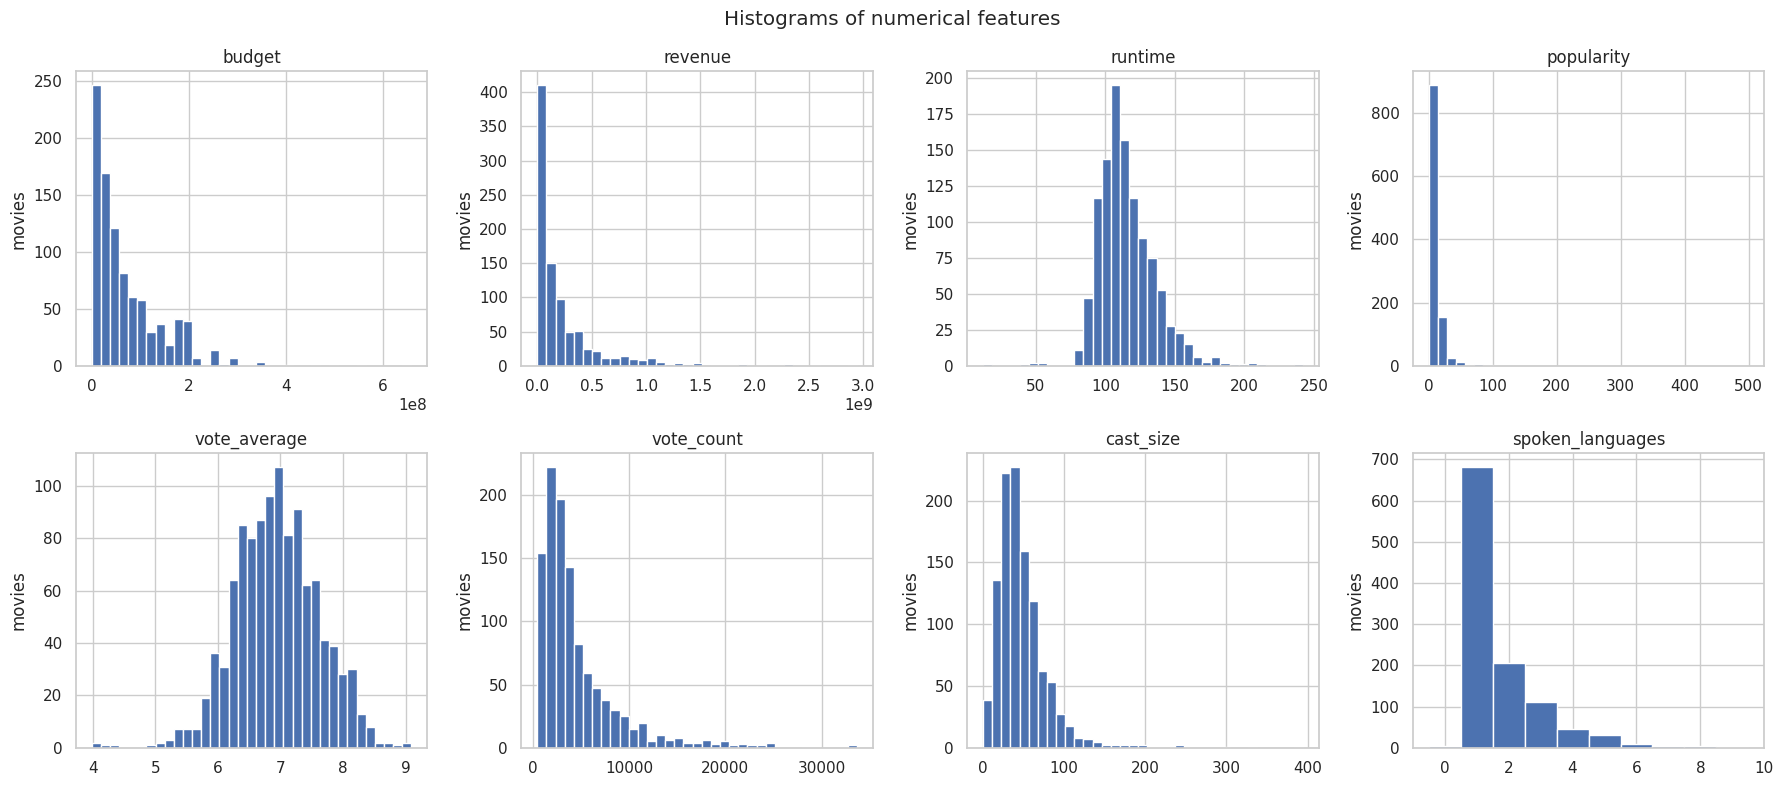

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, c in zip(axes.flat, num_cols):
    if c == "spoken_languages":
        bins = np.arange(-0.5, eda[c].max() + 1.5)
    else:
        bins = 35
    ax.hist(eda[c].dropna(), bins=bins, edgecolor="white")
    ax.set(title=c, ylabel="movies")

fig.suptitle("Histograms of numerical features")
plt.tight_layout()
plt.show()

I plotted histograms to see how each numerical feature is distributed. Budget, revenue, popularity, vote_count, cast_size and spoken_languages are right-skewed: most films have lower values, while a few have much higher ones. vote_average is roughly symmetric, with most films around 6 to 8. Runtime is mostly around 100 to 130 minutes, with a longer tail towards long films. The uneven distributions will be examined further using skewness analysis in Section 7.

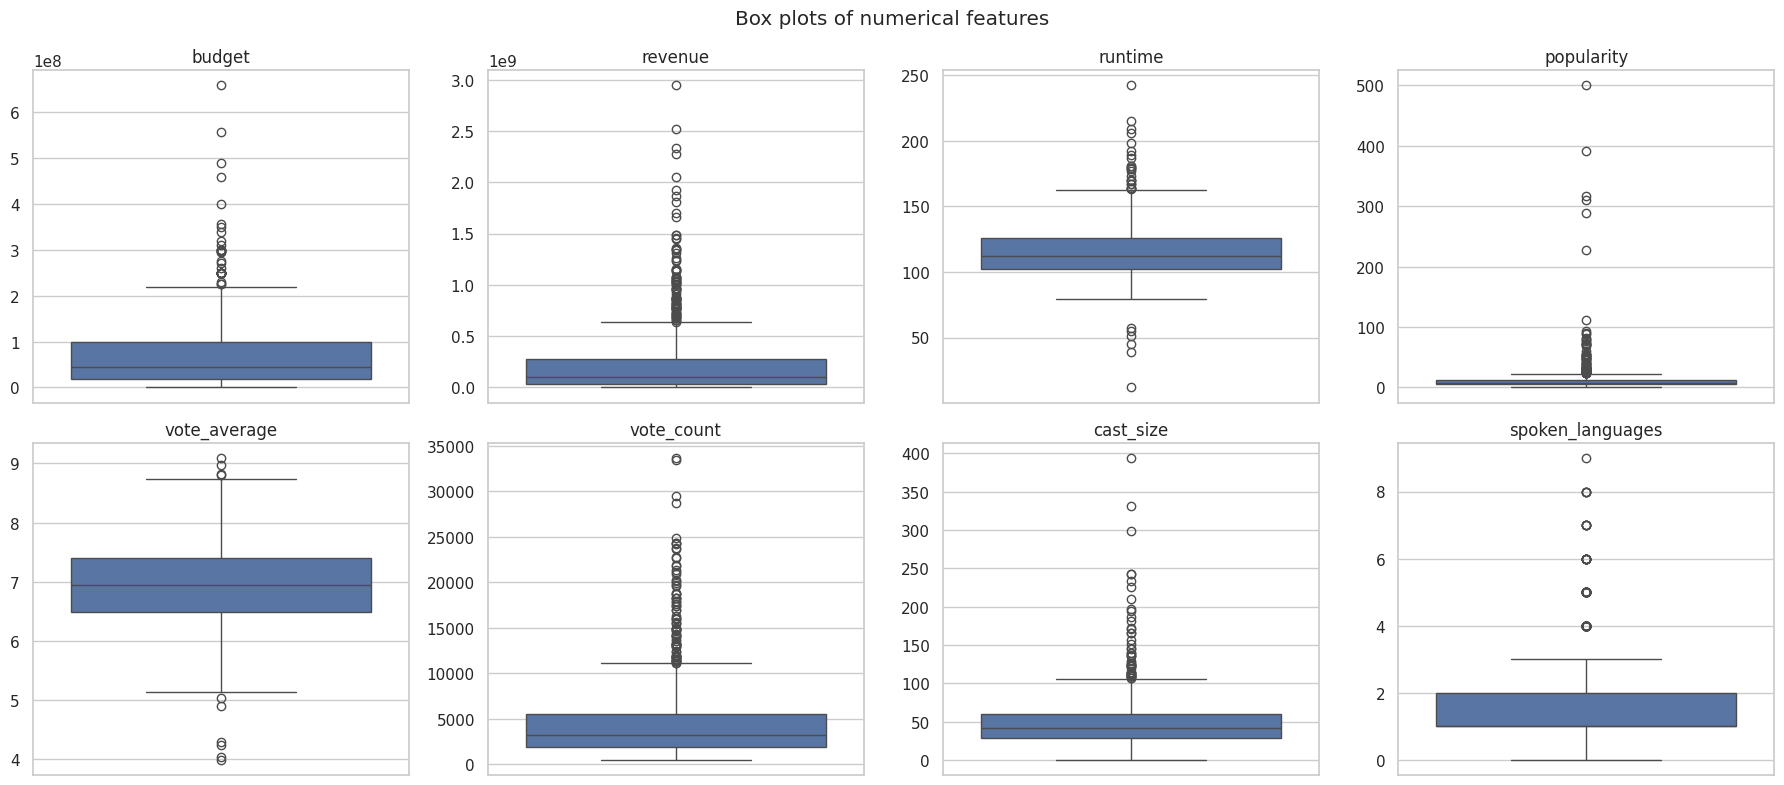

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(y=eda[c], ax=ax)
    ax.set(title=c, ylabel="")

fig.suptitle("Box plots of numerical features")
plt.tight_layout()
plt.show()

I plotted box plots to find potential outliers in the numerical features. Budget, revenue, popularity, vote_count, cast_size and spoken_languages have many points above the upper whisker. Runtime and vote_average have potential outliers on both the low and high sides. Popularity's box looks very compressed because a few very large values stretch the scale. These points are unusual but not necessarily errors, since very high budgets or revenues can be real blockbusters. I will examine them using the IQR method in Section 8 before deciding how to treat them.

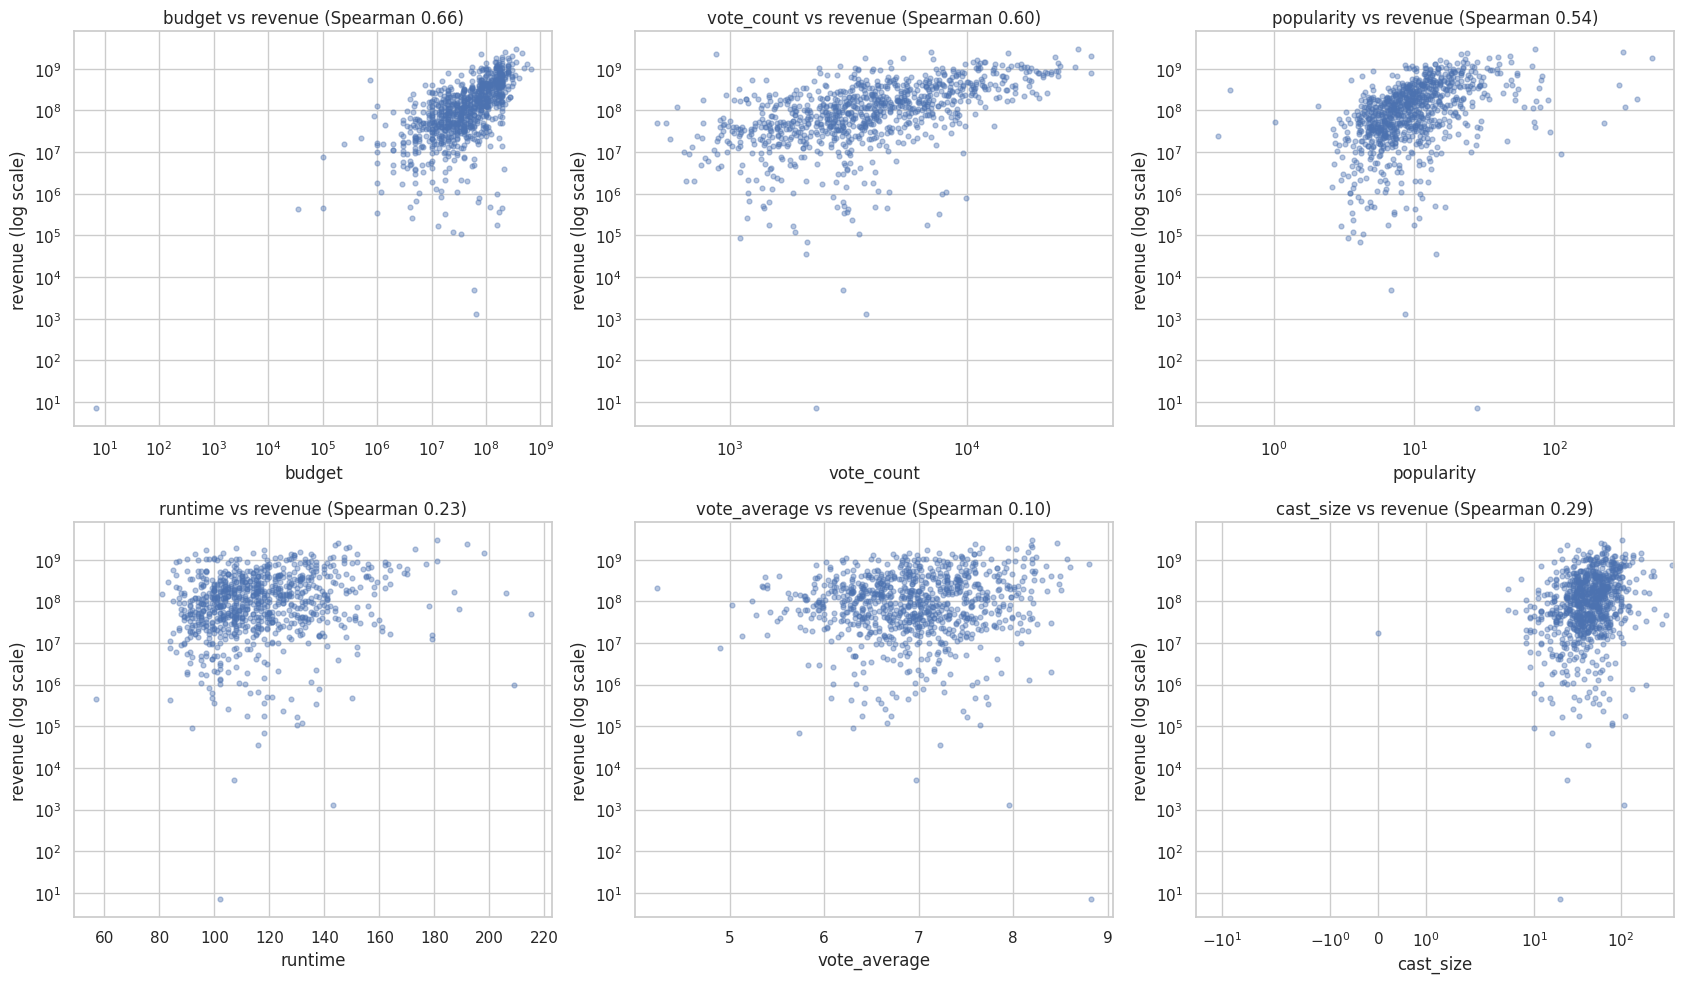

In [ ]:
pairs = ["budget", "vote_count", "popularity", "runtime", "vote_average", "cast_size"]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, c in zip(axes.flat, pairs):
    d = eda[[c, "revenue"]].dropna()
    ax.scatter(d[c], d["revenue"], s=12, alpha=0.4)
    ax.set_yscale("log")
    if c in ["budget", "vote_count", "popularity"]:
        ax.set_xscale("log")
    elif c == "cast_size":
        ax.set_xscale("symlog")
    rho = d[c].corr(d["revenue"], method="spearman")
    ax.set(xlabel=c, ylabel="revenue (log scale)",
           title=f"{c} vs revenue (Spearman {rho:.2f})")

plt.tight_layout()
plt.show()

I used scatter plots to see how six numerical features relate to revenue. Budget (Spearman 0.66), vote_count (0.60) and popularity (0.54) show upward trends, so higher values generally go with higher revenue, although the points are spread out. cast_size (0.29) and runtime (0.23) have weak relationships, and vote_average (0.10) has a very weak one. The isolated points near the bottom are films with very small recorded revenue, some of which may be the suspicious values noted earlier. These plots show associations, not that one feature causes higher revenue. popularity and vote_count can also grow after release, so they could cause leakage in a pre-release prediction.

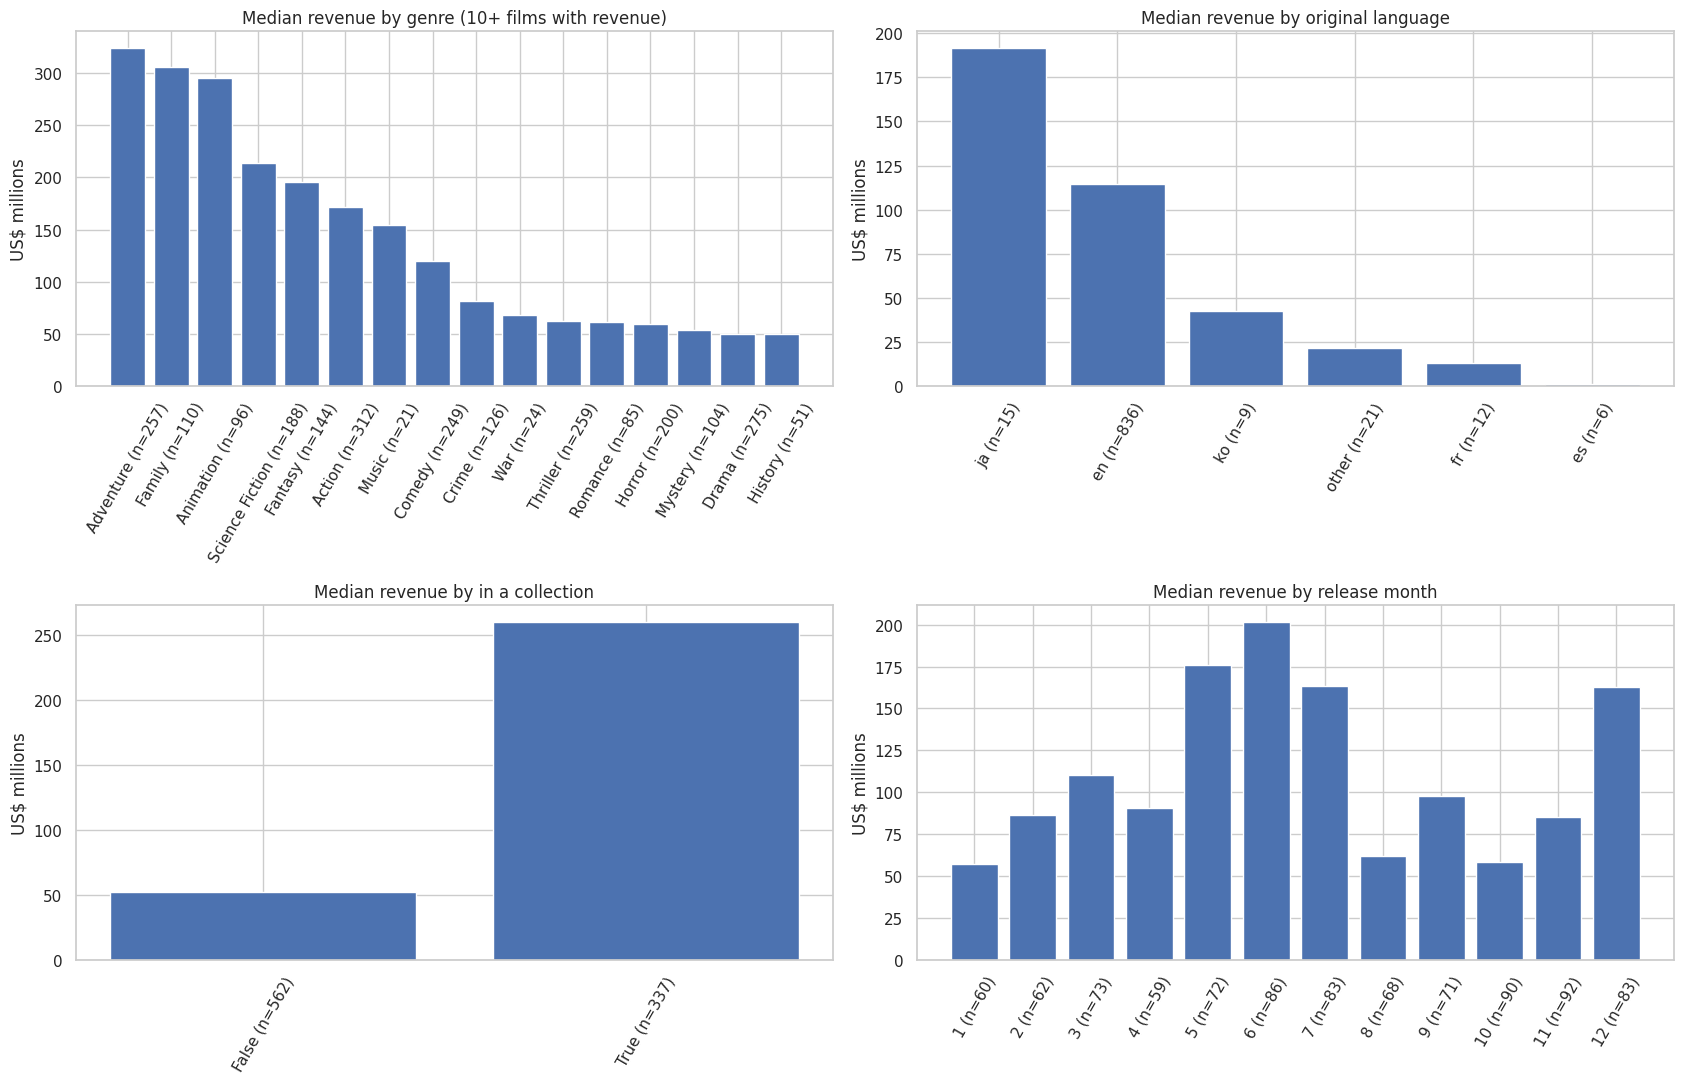


genre (10+ films with revenue)
                   n  median
genre                       
Adventure        257   323.7
Family           110   305.7
Animation         96   295.3
Science Fiction  188   213.9
Fantasy          144   195.3
Action           312   171.6
Music             21   154.6
Comedy           249   120.1
Crime            126    82.1
War               24    68.4
Thriller         259    62.2
Romance           85    61.6
Horror           200    59.9
Mystery          104    54.4
Drama            275    50.1
History           51    50.1

original language
                     n  median
original_language             
ja                  15   191.4
en                 836   114.5
ko                   9    42.7
other               21    21.7
fr                  12    13.1
es                   6     1.1

in a collection
                 n  median
in_collection             
False          562    52.5
True           337   259.9

release month
                n  median
release_month

In [ ]:
g = eda.assign(genre=eda["genres"].str.split("|")).explode("genre")
top_lang = eda["original_language"].value_counts().head(5).index
lang = eda["original_language"].where(eda["original_language"].isin(top_lang), "other")

def group_stats(keys, data):
    return data.groupby(keys)["revenue"].agg(n="count", median="median")

tables = {
    "genre (10+ films with revenue)": group_stats("genre", g).query("n >= 10")
                                      .sort_values("median", ascending=False),
    "original language": group_stats(lang, eda).sort_values("median", ascending=False),
    "in a collection": group_stats("in_collection", eda),
    "release month": group_stats("release_month", eda),
}

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
for ax, (name, t) in zip(axes.flat, tables.items()):
    labels = [f"{i} (n={n})" for i, n in zip(t.index, t["n"])]
    ax.bar(labels, t["median"] / 1e6)
    ax.set(title=f"Median revenue by {name}", ylabel="US$ millions")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

for name, t in tables.items():
    print("\n" + name)
    print(t.assign(median=(t["median"] / 1e6).round(1)).to_string())

I used bar charts to compare median revenue across groups, using only films with known revenue. Adventure (323.7M), Family (305.7M) and Animation (295.3M) have the highest genre medians, while Drama and History have the lowest (50.1M). Films in a collection have a much higher median (259.9M) than other films (52.5M). June (201.6M), May (176.1M), July (163.7M) and December (162.7M) are the highest release months. Japanese has the highest language median (191.4M), but it is based on only 15 films, and the other non-English groups are also small, so these results need caution. A film can belong to several genres. These comparisons do not account for other factors such as budget, so they do not show that a group causes higher revenue.

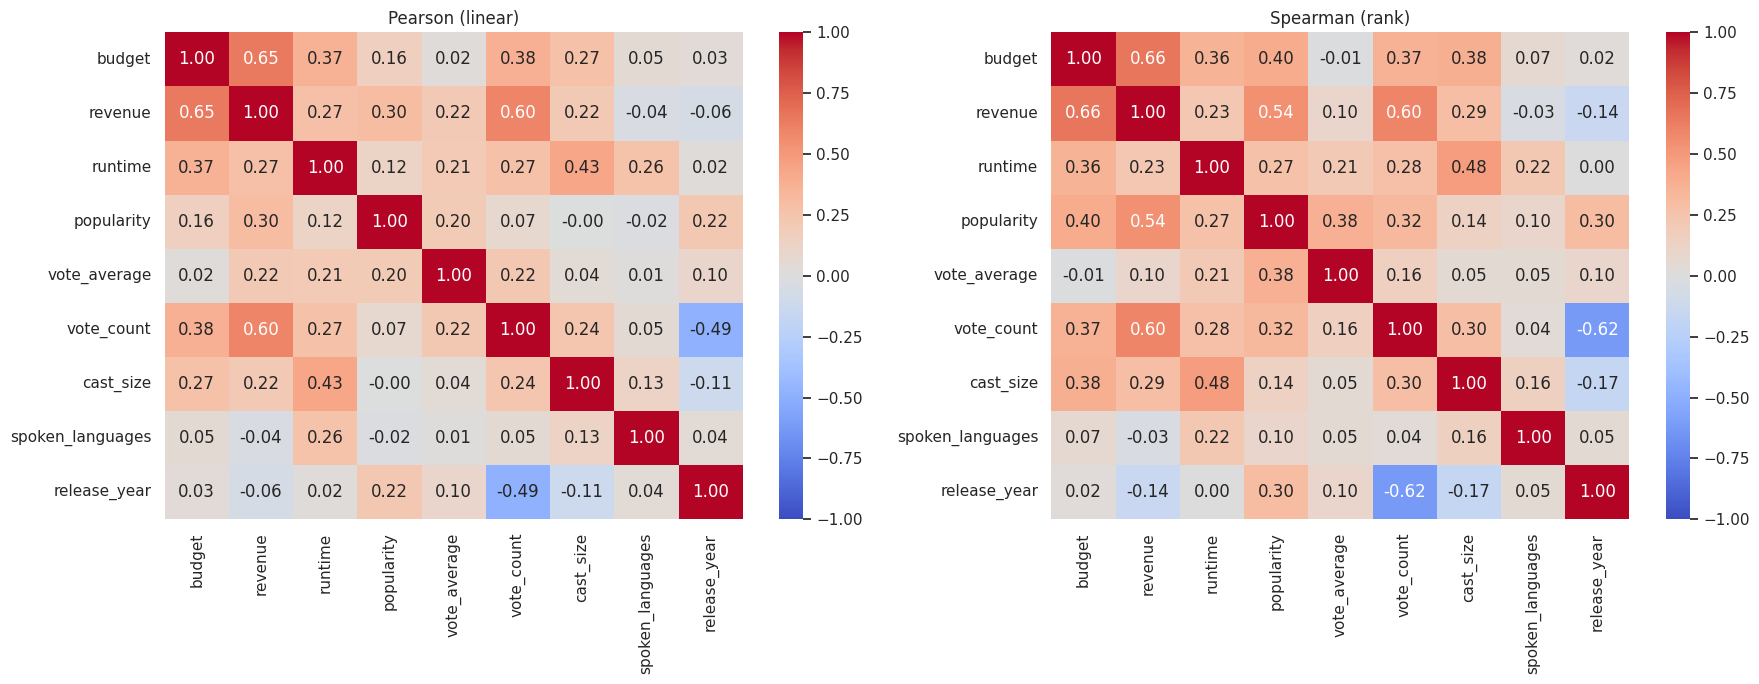

Correlation with revenue:
                  pearson  spearman
budget               0.65      0.66
vote_count           0.60      0.60
popularity           0.30      0.54
cast_size            0.22      0.29
runtime              0.27      0.23
vote_average         0.22      0.10
spoken_languages    -0.04     -0.03
release_year        -0.06     -0.14


In [ ]:
corr_cols = num_cols + ["release_year"]
pearson = eda[corr_cols].corr()
spearman = eda[corr_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, m, name in zip(axes, [pearson, spearman], ["Pearson (linear)", "Spearman (rank)"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("Correlation with revenue:")
print(pd.DataFrame({"pearson": pearson["revenue"], "spearman": spearman["revenue"]})
      .drop("revenue").sort_values("spearman", ascending=False).round(2))

I used Pearson and Spearman heatmaps to examine relationships between the numerical variables. Budget has the strongest relationship with revenue (Pearson 0.65, Spearman 0.66), followed by vote_count (0.60 for both). Popularity's value rises from 0.30 with Pearson to 0.54 with Spearman, which suggests that its relationship with revenue is not well described by a straight line or is affected by extreme values. The strongest relationship between two input features is between release_year and vote_count (Pearson -0.49, Spearman -0.62): newer films tend to have fewer votes, possibly because they have had less time to collect them. No pair of input features is close to a perfect correlation. Correlation does not show that one variable causes another.

# SECTION 7: Skewness Analysis and Treatment

,skew,interpretation
budget,2.10,high positive
revenue,3.08,high positive
runtime,1.12,high positive
cast_size,2.19,high positive
spoken_languages,2.15,high positive
n_genres,0.35,approximately symmetric
n_companies,1.52,high positive


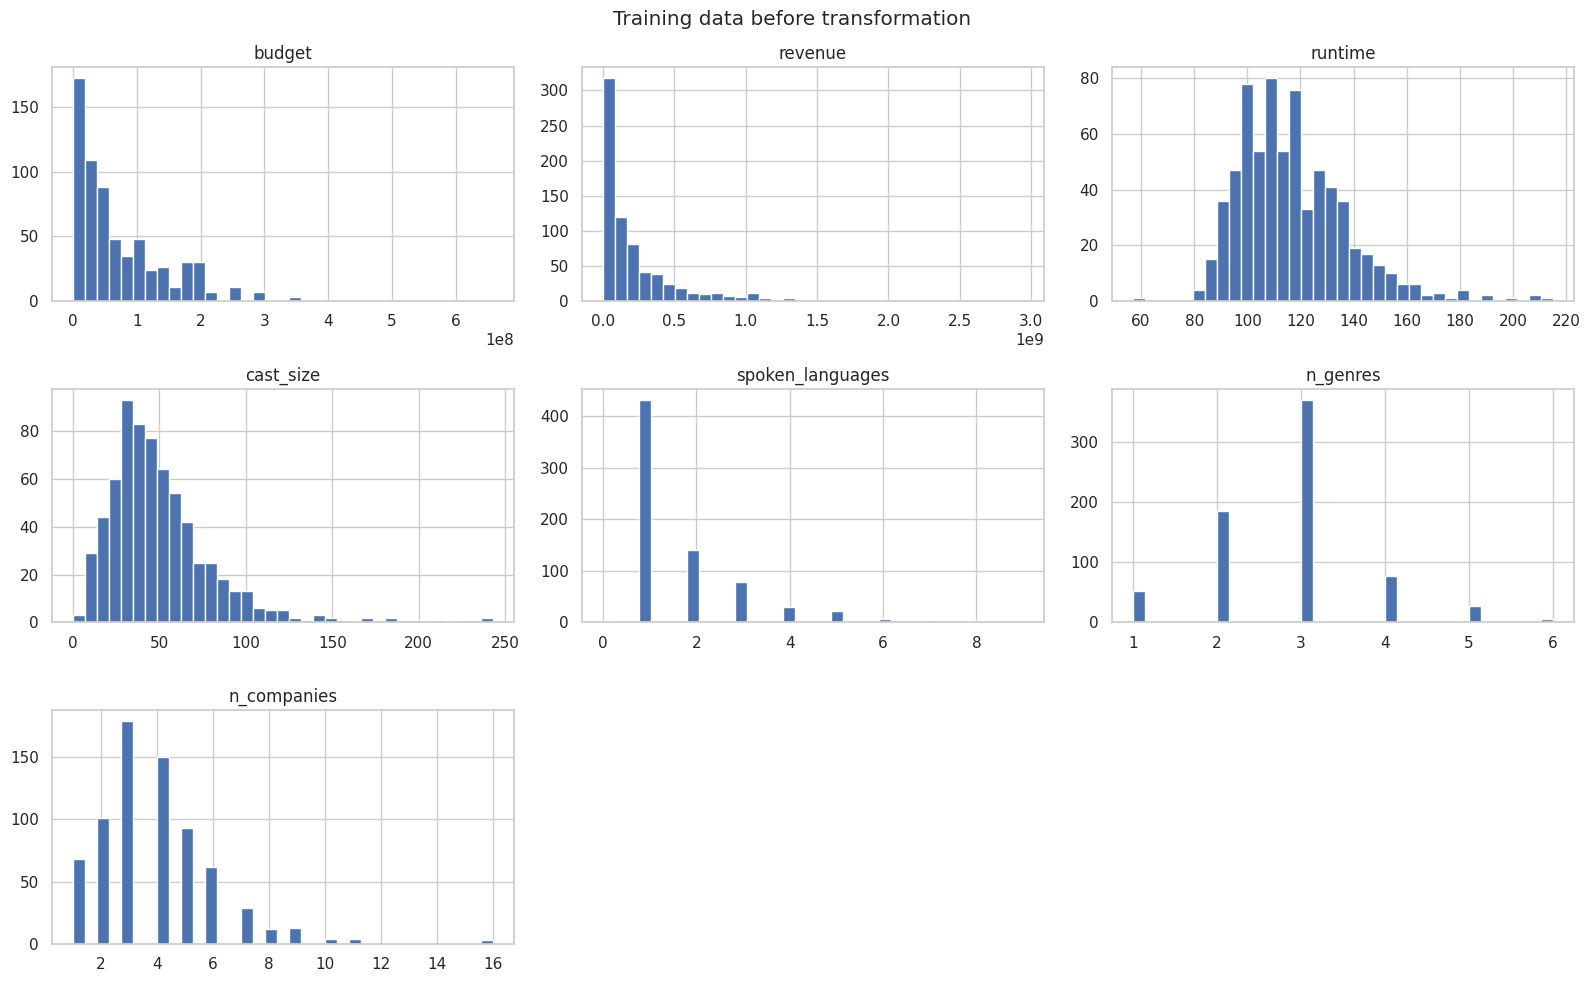

In [ ]:
skew_cols = ["budget", "revenue", "runtime", "cast_size",
             "spoken_languages", "n_genres", "n_companies"]
train_num = X_train.assign(revenue=y_train)[skew_cols]

def label(s):
    if abs(s) < 0.5:
        return "approximately symmetric"
    size = "moderate" if abs(s) <= 1 else "high"
    direction = "positive" if s > 0 else "negative"
    return f"{size} {direction}"

skew_before = train_num.skew()
display(pd.DataFrame({"skew": skew_before.round(2),
                      "interpretation": skew_before.map(label)}))

train_num.hist(bins=35, figsize=(16, 10), edgecolor="white")
plt.suptitle("Training data before transformation")
plt.tight_layout()
plt.show()

I calculated skewness on the training data and plotted histograms to find which numerical columns need treatment. I used only training data so that the test set does not influence my choices. I treated an absolute skew below 0.5 as approximately symmetric, 0.5 to 1 as moderate and above 1 as high. Revenue (3.08), cast_size (2.19), spoken_languages (2.15), budget (2.10), n_companies (1.52) and runtime (1.12) are highly positively skewed. n_genres (0.35) is approximately symmetric. No column has meaningful negative skew. I excluded popularity and the vote columns from this analysis because they are no longer model inputs. I will compare transformations next and apply them only where they help.

In [ ]:
transforms = {
    "none": lambda s: s,
    "sqrt": np.sqrt,
    "cbrt": np.cbrt,
    "log1p": np.log1p,
}

comparison_skew = pd.DataFrame({
    name: {c: func(train_num[c]).skew() for c in skew_cols}
    for name, func in transforms.items()
})
display(comparison_skew.round(2))

,none,sqrt,cbrt,log1p
budget,2.10,0.68,0.25,-2.45
revenue,3.08,1.25,0.62,-1.85
runtime,1.12,0.79,0.68,0.48
cast_size,2.19,0.81,0.29,-0.53
spoken_languages,2.15,1.31,0.74,1.18
n_genres,0.35,-0.32,-0.55,-0.59
n_companies,1.52,0.40,0.09,-0.09


I compared square root, cube root and log1p to choose transformations. The best option differs by column. Log1p changes budget skew from 2.10 to -2.45, creating a strong skew in the other direction, while cube root reduces it to 0.25. I chose cube root for budget, revenue, cast_size and n_companies, and log1p for runtime. For n_companies, cube root and log1p were similarly close to zero. I left n_genres unchanged because it is already approximately symmetric. I also left spoken_languages unchanged because it is a small whole-number count; although cube root improves its skew to 0.74, it would remain moderately skewed.

,transform,skew_before,skew_after
budget,cbrt,2.10,0.25
revenue,cbrt,3.08,0.62
runtime,log1p,1.12,0.48
cast_size,cbrt,2.19,0.29
n_companies,cbrt,1.52,0.09


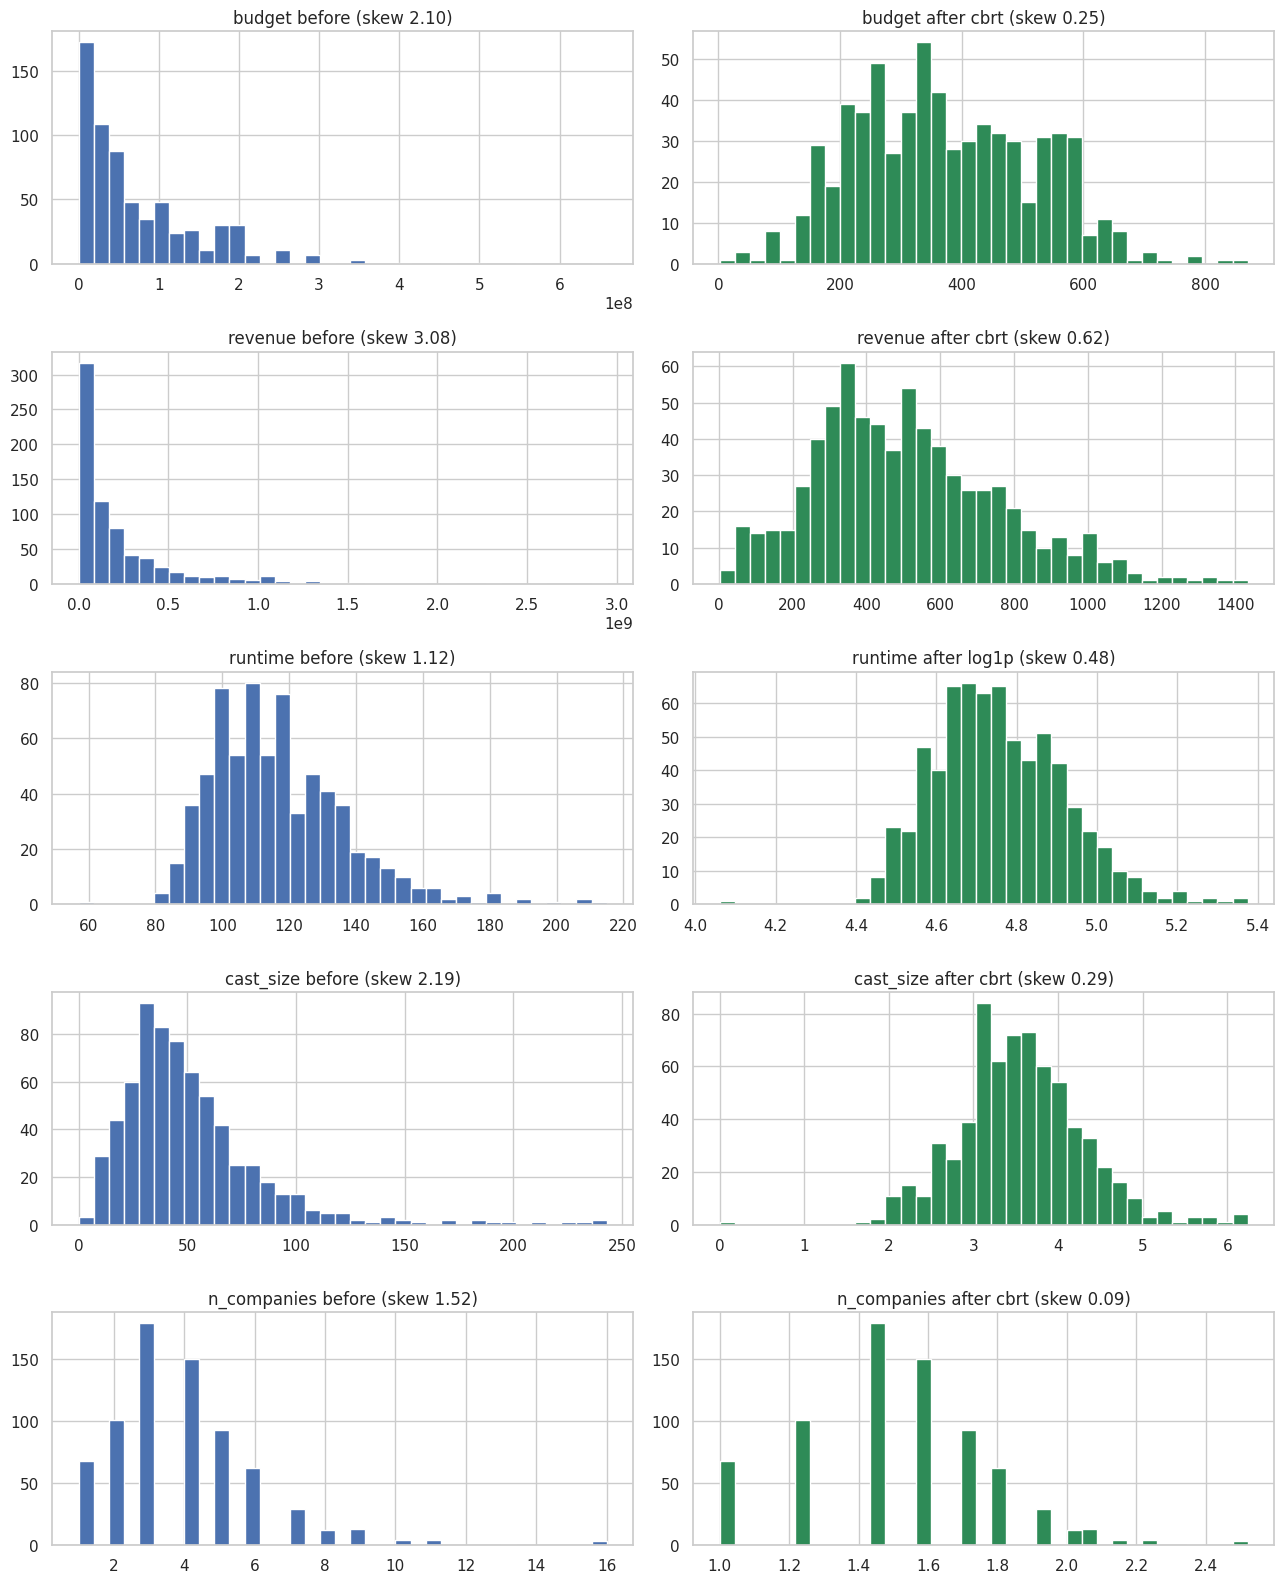

In [ ]:
chosen = {"budget": "cbrt", "revenue": "cbrt", "runtime": "log1p",
          "cast_size": "cbrt", "n_companies": "cbrt"}

result = pd.DataFrame({
    "transform": pd.Series(chosen),
    "skew_before": pd.Series({c: train_num[c].skew() for c in chosen}),
    "skew_after": pd.Series({c: transforms[t](train_num[c]).skew()
                             for c, t in chosen.items()}),
})
display(result.round(2))

fig, axes = plt.subplots(len(chosen), 2, figsize=(13, 16))
for (left, right), (c, t) in zip(axes, chosen.items()):
    left.hist(train_num[c].dropna(), bins=35, edgecolor="white")
    left.set_title(f"{c} before (skew {train_num[c].skew():.2f})")
    new = transforms[t](train_num[c].dropna())
    right.hist(new, bins=35, edgecolor="white", color="seagreen")
    right.set_title(f"{c} after {t} (skew {new.skew():.2f})")
plt.tight_layout()
plt.show()

# transformed copies; X_train and X_test stay unchanged
X_train_t, X_test_t = X_train.copy(), X_test.copy()
for c, t in chosen.items():
    if c != "revenue":
        X_train_t[c] = transforms[t](X_train[c])
        X_test_t[c] = transforms[t](X_test[c])
y_train_t = np.cbrt(y_train)

I applied the chosen transformations and compared skewness and histograms before and after. Budget improved from 2.10 to 0.25, cast_size from 2.19 to 0.29, n_companies from 1.52 to 0.09, runtime from 1.12 to 0.48, and revenue from 3.08 to 0.62. The histograms show that the long right tails became much shorter. By my limits, budget, cast_size, n_companies and runtime are now approximately symmetric, while revenue is still moderately skewed. So the transformations improved the distributions but did not make all of them perfectly symmetric. I stored the transformed values in new variables, so the original data is unchanged. If a model predicts the cube root of revenue, its predictions must be cubed before calculating errors in dollars.

# SECTION 8: Outlier Detection Using the IQR Method


In [ ]:
def fences(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

def iqr_report(data, cols):
    rows = {}
    for c in cols:
        q1, q3, iqr, low, high = fences(data[c])
        below = int((data[c] < low).sum())
        above = int((data[c] > high).sum())
        percent = 100 * (below + above) / data[c].count()
        rows[c] = [q1, q3, iqr, low, high, below, above, below + above, percent]
    return pd.DataFrame(rows, index=["Q1", "Q3", "IQR", "lower", "upper",
                                     "below", "above", "total", "percent"]).T

display(iqr_report(train_num, skew_cols).round(2))

,Q1,Q3,IQR,lower,upper,below,above,total,percent
budget,18000000.0,110000000.0,92000000.0,-1.200000e+08,2.480000e+08,0.0,28.0,28.0,4.26
revenue,35670007.5,297545486.0,261875478.5,-3.571432e+08,6.903587e+08,0.0,68.0,68.0,9.46
runtime,102.0,129.0,27.0,6.150000e+01,1.695000e+02,1.0,14.0,15.0,2.18
cast_size,30.0,63.0,33.0,-1.950000e+01,1.125000e+02,0.0,29.0,29.0,4.27
spoken_languages,1.0,2.0,1.0,-5.000000e-01,3.500000e+00,0.0,66.0,66.0,9.18
n_genres,2.0,3.0,1.0,5.000000e-01,4.500000e+00,0.0,32.0,32.0,4.45
n_companies,3.0,5.0,2.0,0.000000e+00,8.000000e+00,0.0,25.0,25.0,3.48


I calculated Q1, Q3, the IQR and both fences on the training data to find potential outliers. Revenue has 68 (9.46%), spoken_languages 66 (9.18%), n_genres 32 (4.45%), cast_size 29 (4.27%), budget 28 (4.26%), n_companies 25 (3.48%) and runtime 15 (2.18%). Runtime has 1 value below its lower fence; all the other flagged values are above the upper fences. For spoken_languages, the upper fence of 3.5 means that any film with 4 or more languages is flagged, even though this can be perfectly real. So these are potential outliers and not necessarily errors. I will check the films before deciding how to treat them.

In [ ]:
train_titles = df.loc[X_train.index, "title"]

for c in ["budget", "revenue", "runtime", "cast_size", "n_companies"]:
    low, high = fences(train_num[c])[3:]
    mask = (train_num[c] < low) | (train_num[c] > high)
    out = train_num.loc[mask].assign(title=train_titles[mask])
    cols_show = list(dict.fromkeys(["title", c, "budget", "revenue"]))
    print(f"\n{c}: five largest of {len(out)} outliers")
    print(out.nlargest(5, c)[cols_show].to_string(index=False))

low = fences(train_num["runtime"])[3]
short = train_num["runtime"] < low
print("\nShort-runtime outliers:")
print(pd.DataFrame({"title": train_titles[short],
                    "runtime": train_num.loc[short, "runtime"]}).to_string(index=False))


budget: five largest of 28 outliers
                                    title      budget      revenue
                  Jurassic World Dominion 658800000.0 1004004592.0
                     Deadpool & Wolverine 556800000.0 1338073645.0
         Star Wars: The Rise of Skywalker 489900000.0 1074144248.0
                 Avatar: The Way of Water 460000000.0 2334484620.0
Mission: Impossible - The Final Reckoning 400000000.0  598767057.0

revenue: five largest of 68 outliers
                    title      revenue      budget
        Avengers: Endgame 2942661253.0 356000000.0
Spider-Man: Brand New Day 2523147515.0 225000000.0
 Avatar: The Way of Water 2334484620.0 460000000.0
                 Ne Zha 2 2270700370.0  80000000.0
   Avengers: Infinity War 2052415039.0 300000000.0

runtime: five largest of 15 outliers
                     title  runtime      budget      revenue
             The Brutalist    215.0   9600000.0   50145227.0
              The Irishman    209.0 159000000.0     96885

I checked the outlier films before deciding what to do. The largest budgets and revenues include big releases such as Jurassic World Dominion and Avengers: Endgame, and the longest runtimes include The Brutalist and The Irishman. These appear to be genuine films with unusual values, although I did not verify the figures with another source. The Irishman's recorded revenue (968,853) is very small compared with its budget (159 million), so unusual figures like this should be treated with caution. The only short-runtime outlier in the training data is Host (57 minutes). I will not delete these rows, because unusual values are not necessarily errors, and removing them would take away films such as blockbusters that the model should also handle.

In [ ]:
cap_cols = ["budget", "runtime", "cast_size"]

# fences come from the transformed TRAINING data only
bounds = {c: fences(X_train_t[c])[3:] for c in cap_cols}

X_train_c, X_test_c = X_train_t.copy(), X_test_t.copy()
for c, (low, high) in bounds.items():
    X_train_c[c] = X_train_t[c].clip(low, high)
    X_test_c[c] = X_test_t[c].clip(low, high)   # same fences, not recalculated

def count_out(data, c):
    low, high = bounds[c]
    return int(((data[c] < low) | (data[c] > high)).sum())

effect = pd.DataFrame({c: {
    "outliers_original": int(iqr_report(train_num, [c])["total"].iloc[0]),
    "after_transform": count_out(X_train_t, c),
    "after_capping": count_out(X_train_c, c),
    "test_values_capped": count_out(X_test_t, c),
} for c in cap_cols}).T

display(effect)
print("Train rows:", len(X_train), "->", len(X_train_c))
print("Test rows:", len(X_test), "->", len(X_test_c))

,outliers_original,after_transform,after_capping,test_values_capped
budget,28,2,0,0
runtime,15,7,0,1
cast_size,29,15,0,4


Train rows: 719 -> 719
Test rows: 180 -> 180


I treated outliers by first using the transformed values and then capping budget, runtime and cast_size at IQR fences calculated from the transformed training data. After transformation, outliers fell from 28 to 2 for budget, 15 to 7 for runtime and 29 to 15 for cast_size. Capping reduced the training counts to zero. I applied the same fences to the test data, changing 1 runtime and 4 cast_size values. I kept all 719 training and 180 test rows. I did not cap n_companies because, after the cube root, its flagged count rose from 25 to 80, including films with just one company. Capping would have changed these valid counts. I also did not cap revenue because it is the target, or spoken_languages and n_genres because they are small whole-number counts. Capping reduces how extreme some values are, and its effect on model performance still needs to be tested.

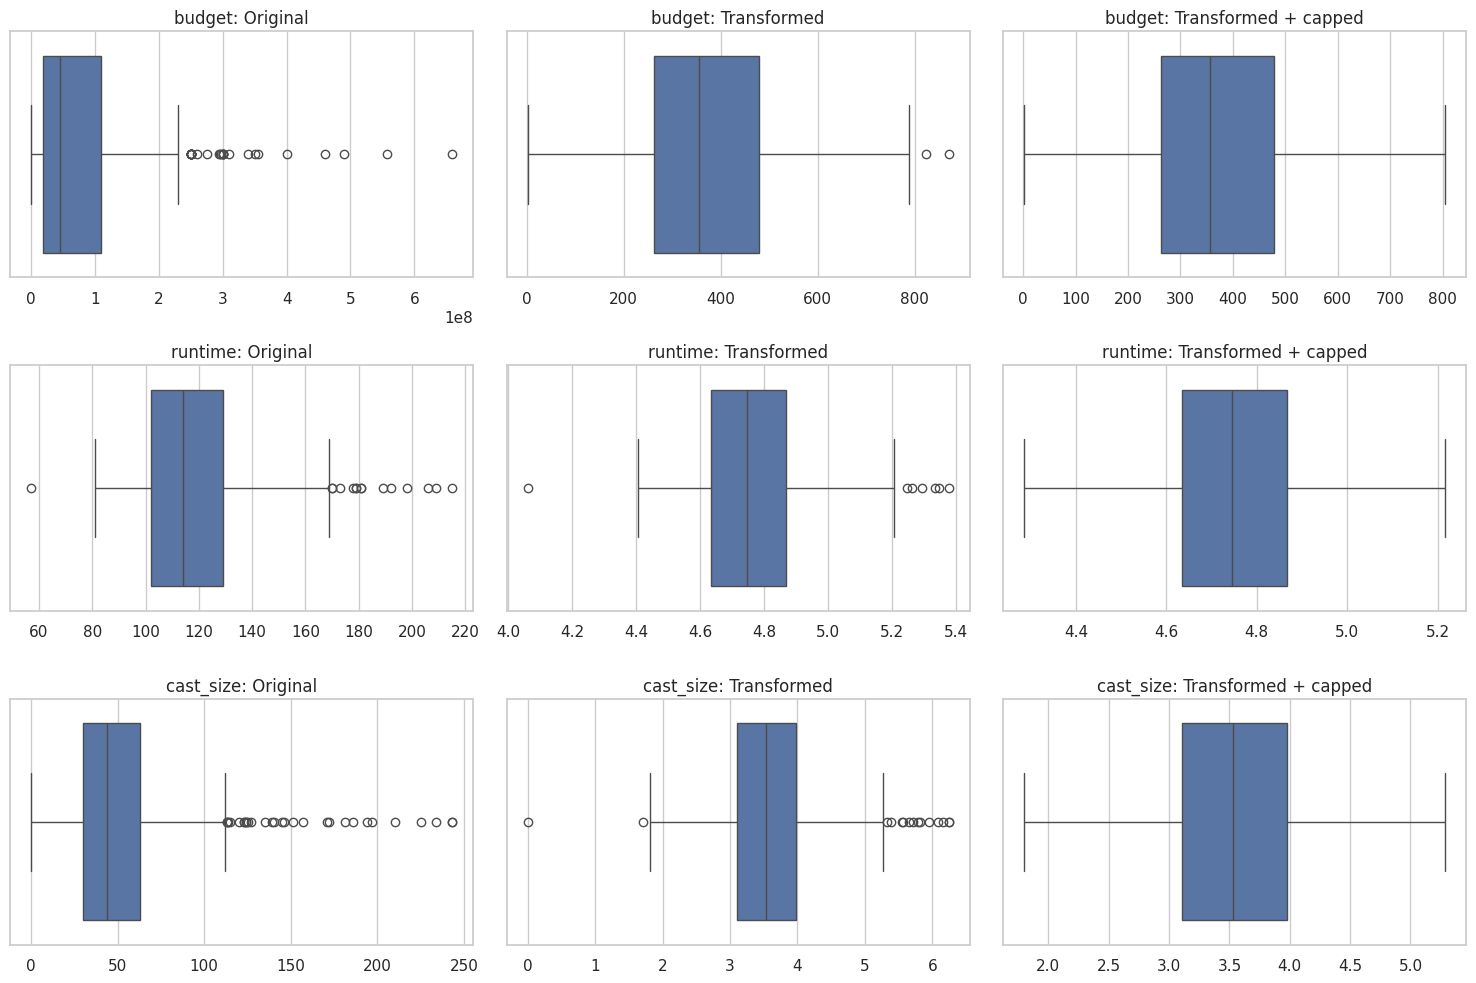

In [ ]:
stages = [("Original", X_train),
          ("Transformed", X_train_t),
          ("Transformed + capped", X_train_c)]

fig, axes = plt.subplots(len(cap_cols), 3, figsize=(15, 10))

for row, c in zip(axes, cap_cols):
    for ax, (name, data) in zip(row, stages):
        sns.boxplot(x=data[c], ax=ax)
        ax.set(title=f"{c}: {name}", xlabel="")

plt.tight_layout()
plt.show()

I compared box plots of budget, runtime and cast_size before treatment, after transformation and after capping. The original plots have many points beyond the whiskers. After transformation, there are fewer outliers, especially for budget, which has only 2 left, while runtime has 7 and cast_size 15. After capping, no training values lie outside the fences used for treatment. This is expected, because capping moves values beyond a fence to the fence itself. The scales differ between panels because the transformed values are not in the original units. Fewer outliers does not prove that a model will perform better, so this still needs to be tested.

# SECTION 14: Advanced Techniques

Missingness Pattern Analysis

I chose missingness pattern analysis because unknown budgets (159) and revenues (201) are the main missing-data problem in this dataset. If these gaps follow a pattern, removing or filling them could affect my results. I use only the real gaps, not the artificial ones.

In [ ]:
m = eda.copy()
m["budget_missing"] = m["budget"].isna()
m["revenue_missing"] = m["revenue"].isna()

display(pd.crosstab(m["budget_missing"], m["revenue_missing"], margins=True))

phi = m["budget_missing"].astype(int).corr(m["revenue_missing"].astype(int))
print(f"Phi correlation between the two missing flags: {phi:.2f}")

with_gap = m.loc[m["budget_missing"], "revenue_missing"].mean()
without_gap = m.loc[~m["budget_missing"], "revenue_missing"].mean()
print(f"Revenue missing when budget is missing: {with_gap:.1%}")
print(f"Revenue missing when budget is present: {without_gap:.1%}")

revenue_missing,False,True,All
budget_missing,,,
False,867,74,941
True,32,127,159
All,899,201,1100


Phi correlation between the two missing flags: 0.66
Revenue missing when budget is missing: 79.9%
Revenue missing when budget is present: 7.9%


I compared the missing budget and revenue values to see whether they happen together. Of the 1,100 films, 127 are missing both, 32 are missing only budget, 74 are missing only revenue, and 867 have both. The phi correlation of 0.66 shows a strong link between the two gaps. Revenue is missing for 79.9% of films with a missing budget, compared with 7.9% of films with a known budget. This shows that the two gaps tend to occur together, but it does not explain why, and one gap does not necessarily cause the other.

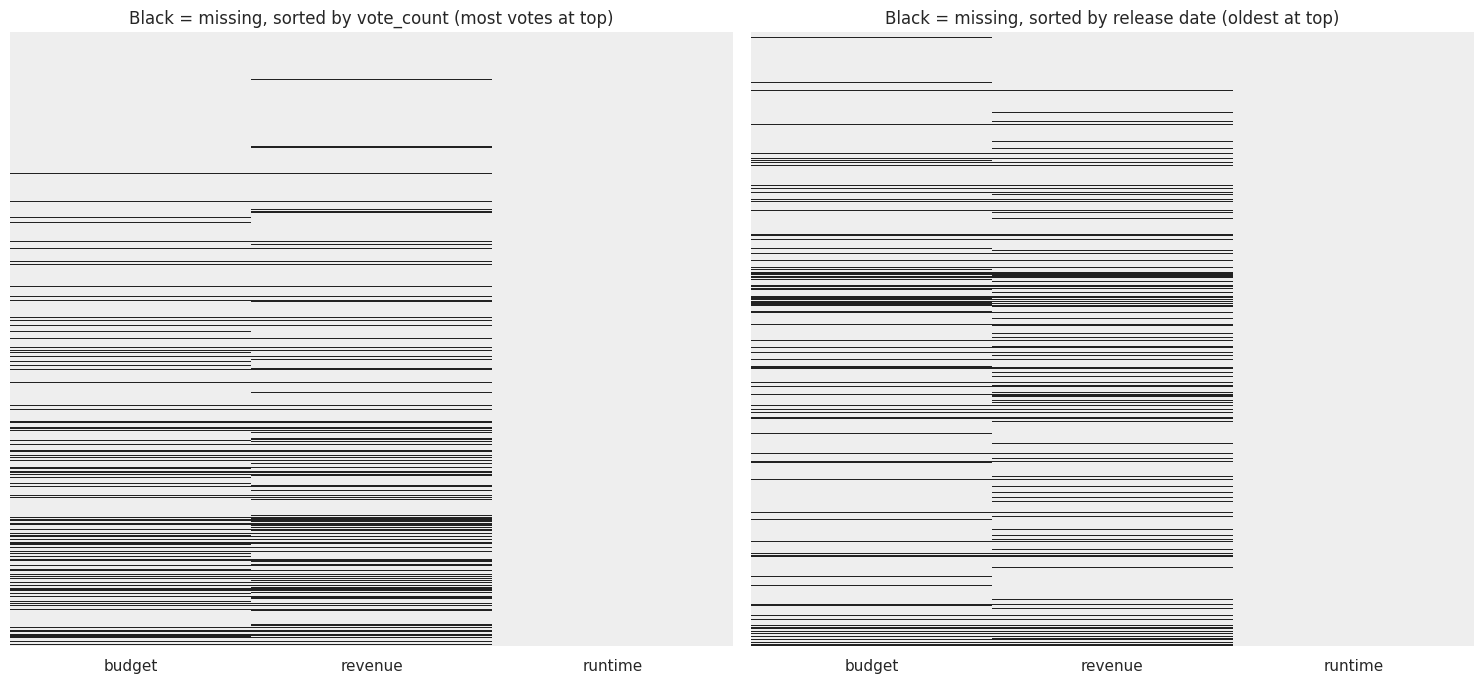

In [ ]:
order_votes = m.sort_values("vote_count", ascending=False)
order_date = m.sort_values("release_date")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, data, name in [
    (axes[0], order_votes, "sorted by vote_count (most votes at top)"),
    (axes[1], order_date, "sorted by release date (oldest at top)")]:
    sns.heatmap(data[["budget", "revenue", "runtime"]].isna(),
                cbar=False, yticklabels=False,
                cmap=["#eeeeee", "#222222"], ax=ax)
    ax.set_title(f"Black = missing, {name}")
plt.tight_layout()
plt.show()

I plotted missingness heatmaps to see whether the gaps change with vote count or release date. When films are sorted by vote count, missing budgets and revenues appear more often towards the bottom, where films have fewer votes. When sorted by release date, there are fewer gaps among the oldest films at the top, while the pattern for later years is uneven. Runtime has no real missing values. The uneven patterns suggest that the gaps may not be completely random, but a picture is not enough to prove this, so I will compare groups and run statistical tests.


release_year
              budget_missing  revenue_missing    n
release_year                                      
2016                     3.0              1.0  100
2017                     3.0              6.0  100
2018                    11.0             14.0  100
2019                    13.0             15.0  100
2020                    38.0             36.0  100
2021                    17.0             23.0  100
2022                    17.0             28.0  100
2023                    13.0             17.0  100
2024                    11.0             16.0  100
2025                     9.0             16.0  100
2026                    24.0             29.0  100

english
         budget_missing  revenue_missing     n
english                                       
False              30.4             20.3    79
True               13.2             18.1  1021

us_production
               budget_missing  revenue_missing     n
us_production                                       
False

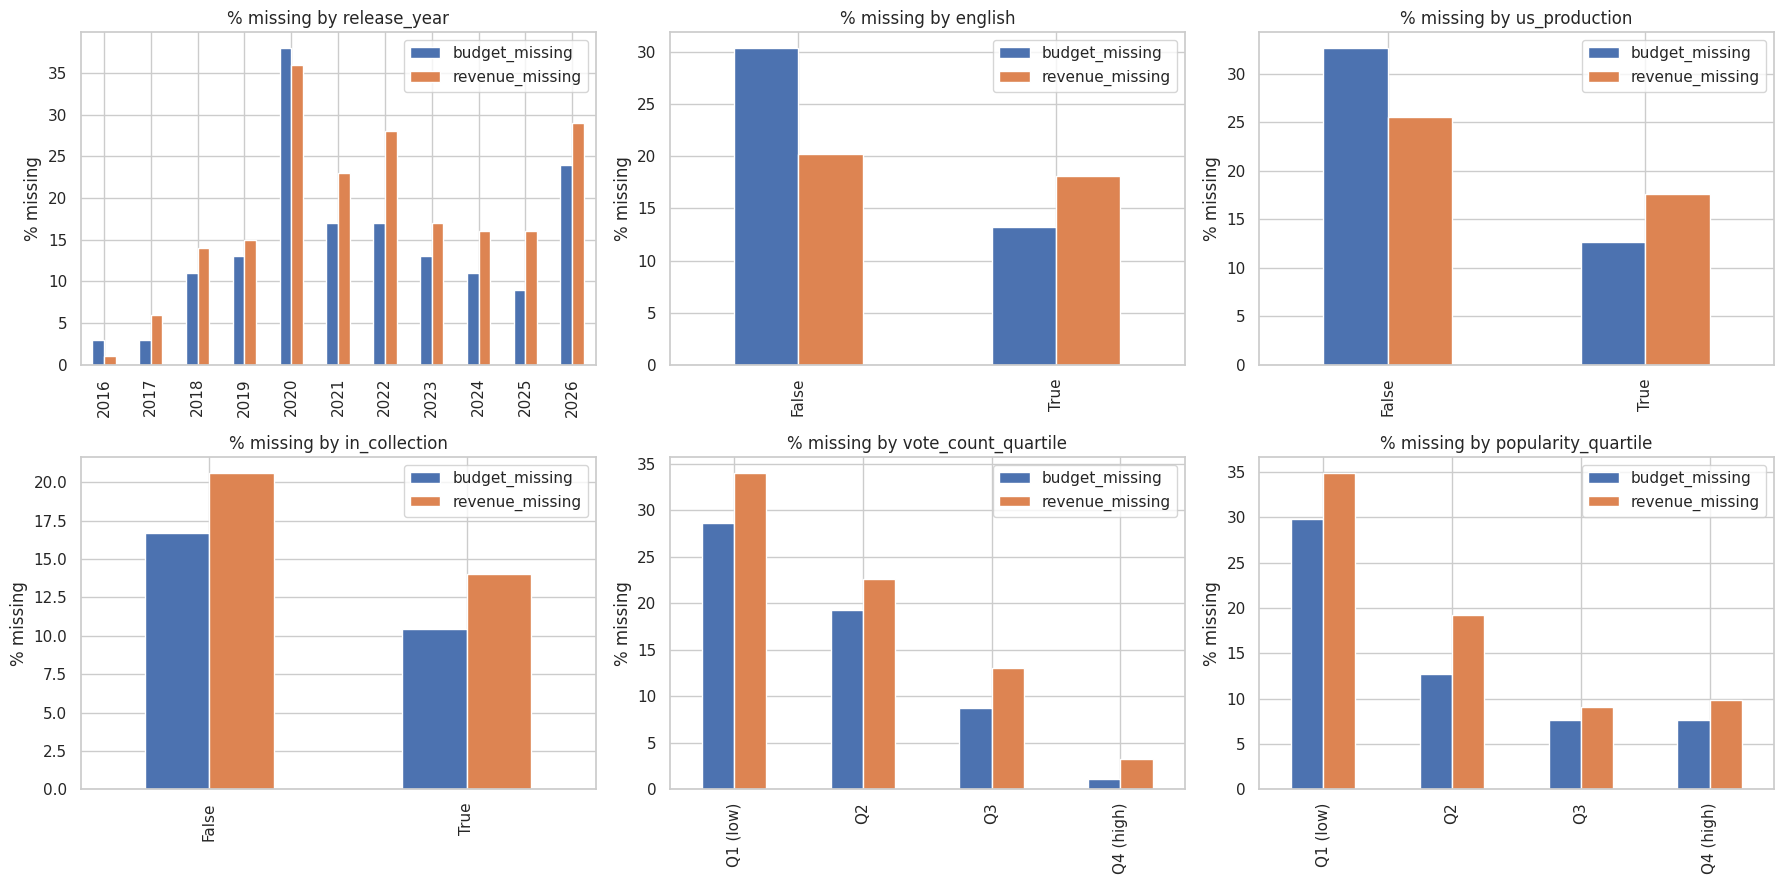

In [ ]:
m["english"] = m["original_language"].eq("en")
m["us_production"] = m["production_countries"].fillna("").str.contains(r"\bUS\b")
for c in ["vote_count", "popularity"]:
    m[c + "_quartile"] = pd.qcut(m[c], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])

groups = ["release_year", "english", "us_production", "in_collection",
          "vote_count_quartile", "popularity_quartile"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.flat, groups):
    grouped = m.groupby(c, observed=True)
    t = grouped[["budget_missing", "revenue_missing"]].mean() * 100
    t.plot.bar(ax=ax)
    ax.set(title=f"% missing by {c}", ylabel="% missing", xlabel="")
    print(f"\n{c}")
    print(t.round(1).assign(n=grouped.size()).to_string())
plt.tight_layout()
plt.show()

I compared the percentage of missing budgets and revenues across different groups. Budget is missing for 28.6% of films in the lowest vote-count quartile and 1.1% in the highest, and revenue for 34.1% and 3.3%. Films in the lowest popularity quartile also have much higher missing rates. Budget is missing more often for non-English films (30.4% against 13.2%) and for films without a US production country (32.7% against 12.7%), while the differences for revenue are smaller. Films not in a collection also have somewhat higher missing rates. By year, 2016 has the lowest rates and 2020 the highest (38% budget, 36% revenue), followed by 2026 for budget, so there is no simple older-versus-newer pattern. The non-English and non-US groups are much smaller (79 and 98 films). I will use statistical tests to check whether these differences could be due to chance.

In [ ]:
from scipy.stats import chi2_contingency, mannwhitneyu

def cramers_v(table):
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

rows = []
for target in ["budget_missing", "revenue_missing"]:
    for c in ["release_year", "english", "us_production", "in_collection"]:
        t = pd.crosstab(m[c], m[target])
        rows.append([target, c, "chi-square", chi2_contingency(t)[1],
                     cramers_v(t), np.nan, np.nan])
    for c in ["vote_count", "popularity", "vote_average", "runtime",
              "cast_size", "spoken_languages"]:
        a = m.loc[m[target], c].dropna()
        b = m.loc[~m[target], c].dropna()
        u, p = mannwhitneyu(a, b)
        rows.append([target, c, "Mann-Whitney U", p,
                     2 * u / (len(a) * len(b)) - 1, a.median(), b.median()])

tests = pd.DataFrame(rows, columns=["missing_flag", "variable", "test", "p",
                     "effect", "median_if_missing", "median_if_present"])

def holm(p):
    order = np.argsort(p.values)
    adj = p.values[order] * (len(p) - np.arange(len(p)))
    adj = np.minimum(1, np.maximum.accumulate(adj))
    out = np.empty(len(p))
    out[order] = adj
    return out

tests["p_holm"] = holm(tests["p"])
tests["significant"] = tests["p_holm"] < 0.05

shown = tests.sort_values(["missing_flag", "p"]).copy()
for c in ["p", "p_holm"]:
    shown[c] = shown[c].map("{:.2g}".format)
print(shown.round(2).to_string(index=False))

   missing_flag         variable           test       p  effect  median_if_missing  median_if_present  p_holm  significant
 budget_missing       vote_count Mann-Whitney U 9.9e-25   -0.51            1889.00            3565.00   2e-23         True
 budget_missing       popularity Mann-Whitney U 6.2e-16   -0.40               5.36               8.68   1e-14         True
 budget_missing     release_year     chi-square 7.4e-13    0.27                NaN                NaN 1.2e-11         True
 budget_missing        cast_size Mann-Whitney U   2e-11   -0.33              31.00              43.00   3e-10         True
 budget_missing    us_production     chi-square 1.8e-07    0.16                NaN                NaN 2.4e-06         True
 budget_missing          runtime Mann-Whitney U 9.7e-07   -0.24             106.00             114.00 1.2e-05         True
 budget_missing          english     chi-square   6e-05    0.13                NaN                NaN  0.0006         True
 budget_missing 

I tested whether the differences could be due to chance, using chi-square tests for categories and Mann-Whitney U tests for numerical variables. Because I ran 20 tests, I used the Holm correction. Vote_count has the largest effect among the numerical variables for both budget (-0.51) and revenue (-0.46) missingness. When budget is missing, the median vote count is 1,889, compared with 3,565 when it is present. Popularity, release year, cast_size and runtime are also significant for both. US production and English language are significant for budget missingness only, with small effects (Cramer's V of 0.16 and 0.13). In_collection, spoken_languages and vote_average are not significant after correction. These results show that missingness is linked to several observed variables, but they do not show what causes it, and some of these variables may overlap with each other.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

Z = pd.DataFrame({
    "log_vote_count": np.log1p(m["vote_count"]),
    "log_popularity": np.log1p(m["popularity"]),
    "vote_average": m["vote_average"],
    "runtime": m["runtime"],
    "log_cast_size": np.log1p(m["cast_size"]),
    "english": m["english"].astype(int),
    "us_production": m["us_production"].astype(int),
    "in_collection": m["in_collection"].astype(int),
})
Z = Z.join(pd.get_dummies(m["release_year"], prefix="year", drop_first=True, dtype=int))

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
for target in ["budget_missing", "revenue_missing"]:
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    auc = cross_val_score(model, Z, m[target], cv=cv, scoring="roc_auc")
    coef = pd.Series(model.fit(Z, m[target])[-1].coef_[0], index=Z.columns)
    print(f"\n{target}: cross-validated AUC = {auc.mean():.2f} +/- {auc.std():.2f}")
    print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(6).round(2).to_string())


budget_missing: cross-validated AUC = 0.84 +/- 0.05
log_vote_count   -1.30
log_popularity   -0.69
vote_average      0.56
year_2020         0.32
year_2019         0.31
log_cast_size    -0.30

revenue_missing: cross-validated AUC = 0.78 +/- 0.01
log_popularity   -0.94
year_2026         0.78
year_2022         0.68
log_vote_count   -0.63
year_2020         0.56
year_2021         0.53


I used logistic regression with 5-fold cross-validation to see whether missing values can be predicted from other columns. The AUC is 0.84 for budget missingness and 0.78 for revenue missingness, well above 0.5, which is chance level. So the gaps can be predicted fairly well, and together with the group tests this is strong evidence that they are not missing completely at random (MCAR). The results are consistent with missing at random (MAR), where missingness depends on observed variables. I cannot rule out missing not at random (MNAR), where it depends on the unknown value itself, because I cannot see the missing amounts. Lower vote count and popularity are linked to a higher chance of a gap in this model. These coefficients show associations, not causes.

In [ ]:
def profile(d):
    return pd.Series({
        "movies": len(d),
        "median vote_count": d["vote_count"].median(),
        "median popularity": d["popularity"].median(),
        "% English": 100 * d["english"].mean(),
        "% US production": 100 * d["us_production"].mean(),
        "% in collection": 100 * d["in_collection"].mean(),
        "% released in 2020": 100 * d["release_year"].eq(2020).mean(),
        "median known budget ($M)": d["budget"].median() / 1e6,
    })

display(pd.DataFrame({
    "all movies (before)": profile(m),
    "revenue known (after)": profile(m[~m["revenue_missing"]]),
    "dropped": profile(m[m["revenue_missing"]]),
}).round(2))

,all movies (before),revenue known (after),dropped
movies,1100.00,899.00,201.00
median vote_count,3184.50,3592.00,1948.00
median popularity,8.08,8.87,5.59
% English,92.82,92.99,92.04
% US production,91.09,91.88,87.56
% in collection,35.64,37.49,27.36
% released in 2020,9.09,7.12,17.91
median known budget ($M),45.00,42.00,50.00


I compared all films with the films left after removing unknown revenue, to see how this changes the sample. The number of films falls from 1,100 to 899. The median vote count rises from 3,184.5 to 3,592, and median popularity from 8.08 to 8.87. The share of films released in 2020 falls from 9.09% to 7.12%, and the share in a collection rises from 35.64% to 37.49%. The 201 dropped films have a median of 1,948 votes, 17.91% were released in 2020, and only 27.36% are in a collection. Among known budgets, the dropped films have a higher median (50 million) than all films (45 million). So the data used for modelling leans towards films with more votes and popularity, and results may not carry over to less visible films. These films still have to be left out of training and testing, because their target value is unknown.

In [ ]:
for data in [X_train, X_test, X_train_t, X_test_t, X_train_c, X_test_c]:
    data["budget_was_missing"] = m.loc[data.index, "budget_missing"]

artificial = X_train["budget"].isna() & ~X_train["budget_was_missing"]

print("Columns in X_train_c:", X_train_c.shape[1] - 1, "->", X_train_c.shape[1])
print("Training films with a real missing budget:", int(X_train_c["budget_was_missing"].sum()))
print("Training films with an artificial budget gap (flag is False):", int(artificial.sum()))
print("Median training revenue ($M) by flag:")
print((y_train.groupby(X_train["budget_was_missing"]).median() / 1e6).round(1))

Columns in X_train_c: 42 -> 43
Training films with a real missing budget: 25
Training films with an artificial budget gap (flag is False): 37
Median training revenue ($M) by flag:
budget_was_missing
False    120.0
True       2.4
Name: revenue, dtype: float64


I added budget_was_missing to the training and test feature tables to keep track of which budgets were originally unknown, because imputation would otherwise hide this. X_train_c went from 42 to 43 columns. In the training data, 25 films have a real missing budget, while 37 other budget gaps were created artificially and are not flagged. The median training revenue is 2.4 million for films with a real missing budget and 120 million for the others. This suggests the flag may be useful, but the group has only 25 films and its effect on model performance has not been tested. The flag also reflects how complete TMDB was when the data was collected, which may include updates made after release, so it could cause leakage in a pre-release prediction. My conclusion is that budget and revenue are unlikely to be missing completely at random. KNN or iterative imputation could be compared with the current median imputation, but neither can remove possible MNAR bias.

In [ ]:
import joblib

feature_names = prep.get_feature_names_out()

pd.DataFrame(X_train_ready, columns=feature_names).to_csv("/content/data/X_train_ready.csv", index=False)
pd.DataFrame(X_test_ready, columns=feature_names).to_csv("/content/data/X_test_ready.csv", index=False)
y_train.to_csv("/content/data/y_train.csv", index=False)
y_test.to_csv("/content/data/y_test.csv", index=False)
joblib.dump(prep, "/content/data/preprocessing_pipeline.joblib")

print(X_train_ready.shape, X_test_ready.shape, len(y_train), len(y_test))

(719, 48) (180, 48) 719 180


In this celli save all the data i need to train the model into files so i can then work on it in the next notebook